# Models Features, Training, Results and Errors

**COS30082 Applied Machine Learning, Assignment 1** · Ling Zhi An (102786768)

In [1]:
# Import libraries
import json
import platform
import sys
import time
import warnings
from collections import Counter, defaultdict
from io import BytesIO
from itertools import pairwise
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import timm
import torch
import torch.nn.functional as F
from IPython.display import Image as JpegImage
from IPython.display import Markdown, display
from PIL import Image
from scipy.stats import fisher_exact
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score

from birdcls.analysis import ensemble_probs, load_source, selective_threshold
from birdcls.audit import flagged_test_images
from birdcls.cam import cam_box, grad_cam
from birdcls.config import TrainConfig
from birdcls.data import build_eval_transform, derive_class_names, load_splits, load_val_split
from birdcls.features import load_features
from birdcls.fileio import read_csv, read_jsonl, sha256_file
from birdcls.metrics import (expected_calibration_error, mcnemar_exact, per_class_accuracy, stratified_bootstrap_ci,
                             summarise, top1_accuracy)
from birdcls.models import build_model, build_optimizer
from birdcls.probe import fit_linear_probe, knn_scores, view_averaged_probs
from birdcls.probs import nll, softmax, tta_probs
from birdcls.runtime import pick_device, synchronize

# Find the repository and import report helpers
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(REPO / "scripts"))
# Display names, ablation labels and the probe table are shared with the report, so both label things alike.
import report_assets as ra  # noqa: E402

# report_assets switches matplotlib to a file-only backend for the report: switch back to inline display.
%matplotlib inline
plt.rcdefaults()
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6,
    "legend.frameon": False,
})
BLUE, ORANGE, GREEN, RED, GRAY, PURPLE = "#2f6b9a", "#e1a03b", "#7a9a3a", "#c0504d", "#9a9a9a", "#8c6bb1"

# Set paths
DATA, META, RESULTS = REPO / "data" / "cub", REPO / "metadata", REPO / "results"
RUN_LOGS, RUNS, FEATURES = RESULTS / "run_logs", REPO / "runs", REPO / "features"
FINAL = "convnext_l_inat21_448"  # the final model's fully logged training run
# Its weights: the first run of the same config and seed, which reproduces FINAL's predictions exactly.
WEIGHTS = RUNS / "convnext_l_inat21_448" / "best_ema.pt"
BUNDLE = REPO / "app" / "bundle"

# Check the input files
needed = [DATA / "Test", RUN_LOGS / FINAL / "metrics.jsonl", RUNS / FINAL / "predictions.npz", RUNS / FINAL / "epochs",
          WEIGHTS, RUNS / "convnext_l_inat21_448" / "gradcam.npz", FEATURES / "convnext_l_inat21@448.npz",
          FEATURES / "resnet50_in1k@448.npz", FEATURES / "app_embeddings.npz", BUNDLE / "calibration.json"]
missing = [str(p.relative_to(REPO)) for p in needed if not p.exists()]
if missing:
    raise FileNotFoundError(f"missing local files (not in git): {missing}")

# Set seeds
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)


# Define helpers
def md_table(header: list[str], rows: list[list]) -> None:
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def show_jpeg(fig: plt.Figure, quality: int = 80) -> None:
    """Display a photo-heavy figure as a JPEG, a tenth of the PNG size, so the saved notebook stays small."""
    buffer = BytesIO()
    fig.savefig(buffer, format="jpeg", dpi=fig.dpi, bbox_inches="tight", pil_kwargs={"quality": quality})
    plt.close(fig)
    display(JpegImage(buffer.getvalue()))


def square(path: Path, size: int = 160) -> np.ndarray:
    """The center square of a photo (the part the evaluation transform keeps), as a thumbnail."""
    with Image.open(path) as im:
        im = im.convert("RGB")
    side = min(im.size)
    left, top = (im.width - side) // 2, (im.height - side) // 2
    return np.asarray(im.crop((left, top, left + side, top + side)).resize((size, size), Image.Resampling.BICUBIC))


def pct(x: float, digits: int = 1) -> str:
    return f"{100 * x:.{digits}f}%"


# Load data, class names and the final model's predictions
train, test = load_splits(DATA)
_, val, _ = load_val_split(DATA, META / "val_split.json")
classes = derive_class_names(train)
C = len(classes)
group_of = np.array([name.split()[-1] for name in classes])  # "... Warbler" -> Warbler
train_photo = {}  # one training photo per species, for galleries
for s in sorted(train, key=lambda s: s.filename):
    train_photo.setdefault(s.label, DATA / "Train" / s.filename)

# Softmax of the photo and its mirror averaged (test-time flip), then one temperature fitted on val.
final = load_source("ConvNeXt-L", RUNS / FINAL / "predictions.npz", calibrate=True)
y_val, y_test = final.labels["val"], final.labels["test"]
p_val, p_test = final.probs["val"], final.probs["test"]
pred_val, pred_test = p_val.argmax(1), p_test.argmax(1)
test_files = final.files["test"]

# Check against the run summary
summary = json.loads((RUN_LOGS / FINAL / "summary.json").read_text())
assert abs(top1_accuracy(y_test, pred_test) - summary["test"]["top1"]) < 1e-12

# Print versions and the final model
device = pick_device()
print(f"Python {platform.python_version()} · torch {torch.__version__} · timm {timm.__version__} · "
      f"scikit-learn {sklearn.__version__} · matplotlib {matplotlib.__version__} · device {device}")
print(f"final model: val top-1 {pct(summary['val']['top1'])}, test top-1 {pct(summary['test']['top1'])} "
      f"(best epoch {summary['best_epoch']} of {summary['epochs_trained']}), temperature {final.temperature:.2f}")

Python 3.14.3 · torch 2.14.0 · timm 1.0.30 · scikit-learn 1.9.1 · matplotlib 3.11.2 · device mps
final model: val top-1 97.5%, test top-1 96.6% (best epoch 10 of 20), temperature 0.73


## 7. How the pretrained networks see the data

Before any fine-tuning, a pretrained network already turns each photo into a feature vector. A **linear probe**, a logistic regression fitted on those frozen vectors, measures how well the vectors separate the 200 species. It costs seconds on a CPU because the features of every photo were extracted once and cached (`scripts/extract_features.py`), which made it possible to compare 14 backbones before spending GPU time on fine-tuning.

### 7.1 Fourteen pretrained backbones

| network | pretraining | type | params (M) | input (px) | feature | probe val | probe test | k-NN test | zero-shot test |
|---|---|---|---|---|---|---|---|---|---|
| BioCLIP 2.5 ViT-H/14 | CLIP on TreeOfLife | ViT | 632 | 224 | pooled | 98.2% | 96.4% | 96.2% | 92.4% |
| EVA-02-L | CLIP → iNat21 | ViT | 314 | 448 | pooled + patch mean | 97.9% | 96.8% | 96.3% | – |
| ConvNeXt-L | CLIP → iNat21 | CNN | 214 | 448 | pooled | 97.8% | 96.1% | 96.3% | – |
| BioCLIP 2 ViT-L/14 | CLIP on TreeOfLife | ViT | 304 | 224 | pooled | 96.8% | 95.9% | 96.0% | 91.7% |
| EVA-02-L | MIM → IN-22k | ViT | 305 | 448 | pooled | 96.8% | 94.1% | 92.9% | – |
| DINOv3 ViT-L/16 | self-supervised | ViT | 303 | 448 | CLS | 95.9% | 94.9% | 92.3% | – |
| DINOv3 ViT-H+/16 | self-supervised | ViT | 840 | 256 | CLS | 95.1% | 94.5% | 88.7% | – |
| DINOv2 ViT-L/14 | self-supervised | ViT | 304 | 448 | pooled | 94.8% | 93.7% | 88.9% | – |
| Swin-L | IN-22k supervised | ViT | 229 | 384 | pooled | 94.5% | 93.5% | 89.5% | – |
| ConvNeXt-L | IN-22k supervised | CNN | 198 | 448 | pooled | 93.7% | 92.8% | 88.4% | – |
| ConvNeXt-L | CLIP → IN-12k | CNN | 200 | 448 | pooled | 93.2% | 90.6% | 86.8% | – |
| SigLIP 2 So400m | image–text (WebLI) | ViT | 428 | 448 | pooled | 93.1% | 91.5% | 84.1% | – |
| ConvNeXt-L | DINOv3, distilled | CNN | 196 | 448 | pooled | 86.6% | 85.6% | 76.6% | – |
| ResNet-50 | IN-1k supervised | CNN | 26 | 448 | pooled | 65.4% | 64.0% | 41.5% | – |

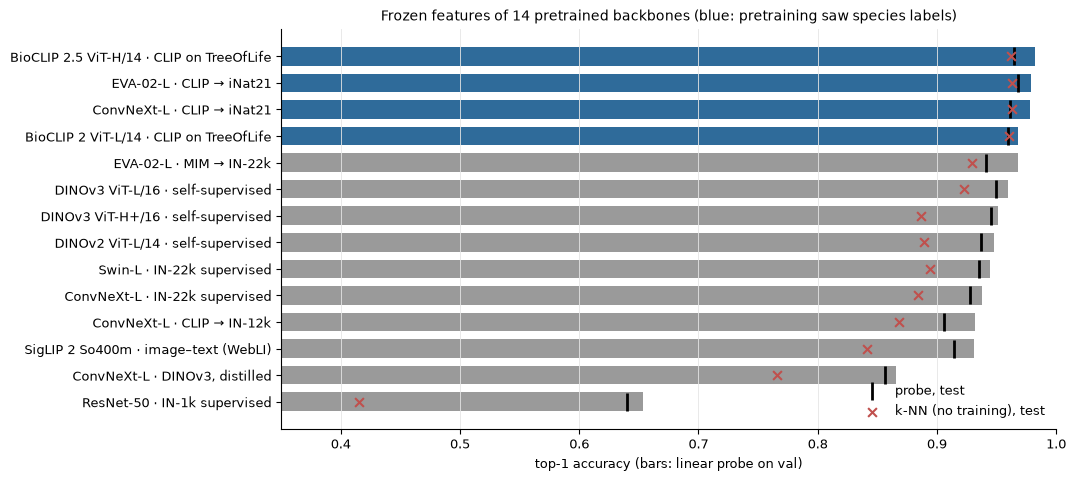

In [2]:
# Load probe results
probes = ra.probe_rows()  # best feature variant per backbone, chosen on val (scripts/report_assets.py)
phase1 = {(r["cache"], r["variant"]): r for r in read_csv(RESULTS / "phase1_probes.csv")}


# Find the phase-1 row of a probe
def phase1_row(row: dict) -> dict:
    cache = row["name"].split(":", 1)[1].split("__")[0]
    return phase1[(cache, row["feature"].replace("_", "+"))]


# Show probe table
md_table(["network", "pretraining", "type", "params (M)", "input (px)", "feature", "probe val", "probe test",
          "k-NN test", "zero-shot test"], [
    [ra.NETWORKS[r["backbone"]][0], ra.NETWORKS[r["backbone"]][1], r["family"], f"{r['params_m']:.0f}",
     r["img_size"], ra.FEATURES[r["feature"]], pct(float(r["val_top1"])), pct(float(r["test_top1"])),
     pct(float(phase1_row(r)["knn_test_top1"])),
     pct(r["zeroshot"]) if r["zeroshot"] == r["zeroshot"] else "–"]
    for r in probes])

# Draw probe accuracies
rows = probes[::-1]
y = np.arange(len(rows))
fig, ax = plt.subplots(figsize=(10, 5.2))

# Draw val bars, test ticks and k-NN marks
ax.barh(y, [float(r["val_top1"]) for r in rows], color=[BLUE if r["in_domain"] else GRAY for r in rows], height=0.7)
ax.scatter([float(r["test_top1"]) for r in rows], y, marker="|", s=160, color="black", linewidths=2, zorder=3,
           label="probe, test")
ax.scatter([float(phase1_row(r)["knn_test_top1"]) for r in rows], y, marker="x", s=40, color=RED, zorder=3,
           label="k-NN (no training), test")

# Set labels and legend
ax.set_yticks(y, [f"{ra.NETWORKS[r['backbone']][0]} · {ra.NETWORKS[r['backbone']][1]}" for r in rows])
ax.set(xlim=(0.35, 1.0), xlabel="top-1 accuracy (bars: linear probe on val)",
       title="Frozen features of 14 pretrained backbones (blue: pretraining saw species labels)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

The four best backbones (blue) are the four whose pretraining saw species labels: iNat21 or the TreeOfLife collection. Pretraining data matters more than architecture. The same ConvNeXt-L architecture scores 86.6 % val with distilled DINOv3 weights, 93.2 % after CLIP and ImageNet-12k, 93.7 % after ImageNet-22k and 97.8 % after CLIP and iNat21. For those four, k-NN, which fits no parameters at all, is within 0.6 pp of the probe on test: neighbors in their feature space already share the species. For general-purpose features, k-NN falls 3–9 pp behind the probe, and for ResNet-50 23 pp (41.5 % against 64.0 %), because their neighbors often share the background or pose rather than the species (section 7.6). BioCLIP 2.5 even reaches 92.4 % zero-shot, from the class names alone, without seeing a single CUB photo.

→ **Decision:** the fine-tuned models come from the top of this chart. ConvNeXt-L and EVA-02-L were fine-tuned (both CLIP, then iNat21), with DINOv3 ViT-L as a self-supervised reference. BioCLIP is an `open_clip` model, which the project's timm-based training code does not fine-tune, so it serves as a frozen probe and an ensemble member only.

### 7.2 Did pretraining already see these species?

The final backbone's last pretraining stage classified iNaturalist 2021's 10,000 species. `scripts/inat21_overlap.py` matched every CUB class to iNaturalist's taxonomy (`metadata/inat21_taxa.json`). A CUB class that is an iNat21 class is a species the network could already name before it saw a single CUB photo, which matters when judging what fine-tuning on 3,870 photos achieved.

In [3]:
# Load the iNat21 class mapping
taxa = json.loads((META / "inat21_taxa.json").read_text())
source = np.array([r["source"] for r in taxa["classes"]])
# "hand-mapped" classes are the ones iNat21 does not have; the two genus-level CUB classes
# (Geococcyx, Sayornis) match iNat21 genera whose species it trained on.
seen = source != "hand-mapped"
print(f"iNat21 has {taxa['inat21_classes']:,} bird species; CUB classes: {taxa['summary']}")
print(f"{seen.sum()} of {C} CUB classes were iNat21 training classes")

# Compare accuracy of seen and unseen classes
correct_test = pred_test == y_test
class_acc = per_class_accuracy(y_test, pred_test, C)
table = []
for name, mask in (("an iNat21 species", source == "iNat21 species"), ("an iNat21 genus", source == "iNat21 genus"),
                   ("not in iNat21", ~seen)):
    photos = mask[y_test]
    table.append([name, mask.sum(), photos.sum(), pct(correct_test[photos].mean()), pct(np.nanmean(class_acc[mask]))])
md_table(["CUB class is", "classes", "test photos", "test top-1", "mean per-class"], table)

# Test the difference
counts = [[(correct_test & m[y_test]).sum(), (~correct_test & m[y_test]).sum()] for m in (seen, ~seen)]
print(f"Fisher's exact test, iNat21 classes against the rest: p = {fisher_exact(counts)[1]:.2f}")

# Print unseen class accuracies
print("classes not in iNat21 (test accuracy):",
      ", ".join(f"{classes[i]} {class_acc[i]:.0%}" for i in np.flatnonzero(~seen)))

iNat21 has 1,486 bird species; CUB classes: {'iNat21 species': 178, 'iNat21 genus': 2, 'hand-mapped': 20}
180 of 200 CUB classes were iNat21 training classes


| CUB class is | classes | test photos | test top-1 | mean per-class |
|---|---|---|---|---|
| an iNat21 species | 178 | 1089 | 96.6% | 96.6% |
| an iNat21 genus | 2 | 10 | 100.0% | 100.0% |
| not in iNat21 | 20 | 105 | 96.2% | 95.7% |

Fisher's exact test, iNat21 classes against the rest: p = 0.78
classes not in iNat21 (test accuracy): Sooty Albatross 100%, Crested Auklet 100%, Least Auklet 100%, Parakeet Auklet 100%, Spotted Catbird 100%, Chuck will Widow 100%, Red faced Cormorant 100%, Mangrove Cuckoo 100%, Ivory Gull 100%, Slaty backed Gull 83%, Green Violetear 100%, Long tailed Jaeger 100%, Pomarine Jaeger 100%, Red legged Kittiwake 100%, Whip poor Will 50%, Horned Puffin 100%, Baird Sparrow 100%, Seaside Sparrow 100%, Black capped Vireo 80%, Swainson Warbler 100%


180 of the 200 CUB classes were iNat21 classes, so the backbone had learned to name them before seeing CUB. The 20 that were not are classified just as well: 96.2 % test top-1 against 96.6 % (Fisher's exact test p = 0.78). The test has little power, since 105 photos and 4 errors could hide a gap of a few points. Still, there is no sign that the accuracy depends on having seen the exact species. The features transfer to related species too. The three weak "unseen" classes, Whip-poor-will (2 of 4), Black-capped Vireo (4 of 5) and Slaty-backed Gull (5 of 6), are hard because of their look-alikes (Chuck-will's-widow, Blue-headed Vireo, the other gulls), not because they are unseen.

→ **Decision:** none needed. The overlap is a class overlap, not a photo overlap (iNat21's photos come from iNaturalist, CUB's from Flickr), and it does not explain the accuracy on its own.

### 7.3 How many photos does each network need? A few-shot learning curve

The assignment provides about 19 fit photos per species. How much accuracy does each pretrained network reach with fewer? The cell fits linear probes on 1, 2, 4 and 8 random fit photos per species (three random draws each) and on all of them, for the ResNet-50 baseline and the final ConvNeXt-L, and scores them on the full val split. Each probe uses the weight decay chosen for it in the full backbone comparison. A k-NN classifier on the same photos needs no fitting at all. Both views of each photo (original and mirror) are training samples; val is scored on the average of the two views, as everywhere in the project.

26 probes and k-NN classifiers in 11 s


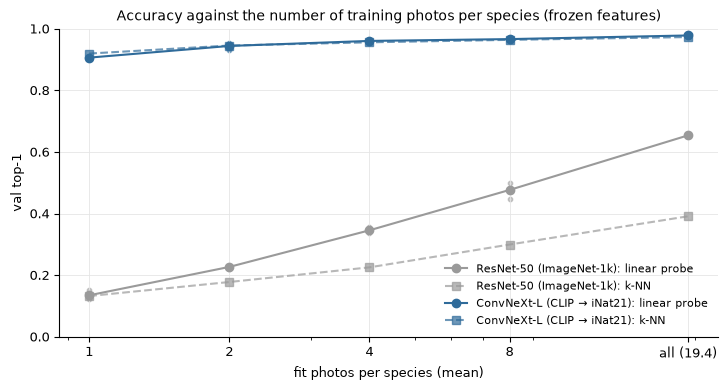

| val top-1 | 1 photo per species | 2 | 4 | 8 | all |
|---|---|---|---|---|---|
| ResNet-50 (ImageNet-1k): linear probe | 13.5% | 22.7% | 34.5% | 47.7% | 65.4% |
| ResNet-50 (ImageNet-1k): k-NN | 13.2% | 17.8% | 22.5% | 29.9% | 39.1% |
| ConvNeXt-L (CLIP → iNat21): linear probe | 90.6% | 94.4% | 96.0% | 96.6% | 97.8% |
| ConvNeXt-L (CLIP → iNat21): k-NN | 91.9% | 94.5% | 95.6% | 96.4% | 97.3% |

In [4]:
# Load frozen features
FROZEN = {"ResNet-50 (ImageNet-1k)": "resnet50_in1k@448", "ConvNeXt-L (CLIP → iNat21)": "convnext_l_inat21@448"}
val_names = {s.filename for s in val}
frozen = {}
for name, cache in FROZEN.items():
    f = load_features(FEATURES / f"{cache}.npz")
    is_train = f["splits"] == "Train"
    is_val = is_train & np.isin(f["filenames"], list(val_names))
    frozen[name] = {"x": f["feat_pooled"].astype(np.float32), "y": f["labels"].astype(np.int64),
                    "files": f["filenames"], "fit": is_train & ~is_val, "val": is_val,
                    "wd": float(phase1[(cache, "pooled")]["best_wd"]), "probe_val": float(phase1[(cache, "pooled")]["val_top1"])}

# Fit probes and k-NN on 1 to all photos per species
SHOTS, DRAWS = [1, 2, 4, 8], 3
curve = defaultdict(list)
start = time.perf_counter()
for name, d in frozen.items():
    x, y_all = d["x"], d["y"]

    # Group fit photos by class
    by_class = defaultdict(list)
    for i in np.flatnonzero(d["fit"]):
        by_class[y_all[i]].append(i)
    val_x, val_y = x[d["val"]], y_all[d["val"]]

    # Fit on a few photos per class, three draws each
    for shots in SHOTS + ["all"]:
        for draw in range(1 if shots == "all" else DRAWS):
            rng = np.random.default_rng(draw)
            chosen = (np.flatnonzero(d["fit"]) if shots == "all" else
                      np.concatenate([rng.choice(v, size=min(shots, len(v)), replace=False) for v in by_class.values()]))
            probe = fit_linear_probe(x[chosen].reshape(-1, x.shape[2]), np.repeat(y_all[chosen], 2), C, d["wd"])
            probe_acc = top1_accuracy(val_y, view_averaged_probs(probe, val_x).argmax(1))
            knn_acc = top1_accuracy(val_y, knn_scores(x[chosen].mean(1), y_all[chosen], val_x.mean(1), C).argmax(1))
            curve[name].append((len(chosen) / C, probe_acc, knn_acc))
    # All fit photos must reproduce the backbone comparison's probe exactly.
    full = curve[name][-1][1]
    assert abs(full - d["probe_val"]) < 1.5e-3, (name, full, d["probe_val"])
print(f"{sum(len(v) for v in curve.values())} probes and k-NN classifiers in {time.perf_counter() - start:.0f} s")

# Draw accuracy against photos per species
fig, ax = plt.subplots(figsize=(8.5, 4))
table = []
for (name, points), color in zip(curve.items(), (GRAY, BLUE)):
    pts = np.array(points)
    shots_axis = np.unique(pts[:, 0].round(2))
    probe_mean = [pts[pts[:, 0].round(2) == s, 1].mean() for s in shots_axis]
    knn_mean = [pts[pts[:, 0].round(2) == s, 2].mean() for s in shots_axis]

    # Draw probe and k-NN curves
    ax.plot(shots_axis, probe_mean, "o-", color=color, label=f"{name}: linear probe")
    ax.plot(shots_axis, knn_mean, "s--", color=color, alpha=0.7, label=f"{name}: k-NN")
    ax.scatter(pts[:, 0], pts[:, 1], color=color, s=10, alpha=0.5)

    # Collect table rows
    table.append([f"{name}: linear probe"] + [pct(v) for v in probe_mean])
    table.append([f"{name}: k-NN"] + [pct(v) for v in knn_mean])

# Set labels and show
ax.set(xscale="log", xticks=[1, 2, 4, 8, 19.35], xticklabels=["1", "2", "4", "8", "all (19.4)"],
       xlabel="fit photos per species (mean)", ylabel="val top-1", ylim=(0, 1),
       title="Accuracy against the number of training photos per species (frozen features)")
ax.legend(loc="lower right", fontsize=8)
plt.show()

# Show table
md_table(["val top-1", "1 photo per species", "2", "4", "8", "all"], table)

With **one** photo per species, the frozen ConvNeXt-L already reaches 90.6 % val (k-NN 91.9 %); four photos give 96.0 %, and all of them (about 19) give 97.8 %. Most of the accuracy is in the pretrained features; the CUB photos mainly place the decision boundaries. The ResNet-50 starts at 13.5 % and is still climbing steeply at 65.4 %: it would profit from far more photos per species than the dataset offers. At one photo per species, k-NN beats the probe for ConvNeXt-L, because a probe fitted on 200 feature vectors of 1,536 dimensions overfits, while k-NN has nothing to fit. Every "all" value reproduces the probe of section 7.1 (checked by an assertion).

→ **Decision:** more CUB data would add little to this backbone (+1.2 pp from 8 photos to all), so effort went into choosing the pretraining and into a fine-tuning scheme that preserves the pretrained features (section 8.5).

### 7.4 The feature space of look-alike species, before and after fine-tuning

t-SNE draws high-dimensional vectors on a plane so that close vectors stay close. Below are the photos of 16 look-alike species (terns, Empidonax flycatchers, Spizella sparrows, two crows) under three embeddings: frozen ResNet-50, frozen ConvNeXt-L, and the fine-tuned ConvNeXt-L (its pre-classifier vector, the one the web app uses to find similar photos). Small dots are fit photos; large outlined dots are val photos, which the fine-tuned network never trained on.

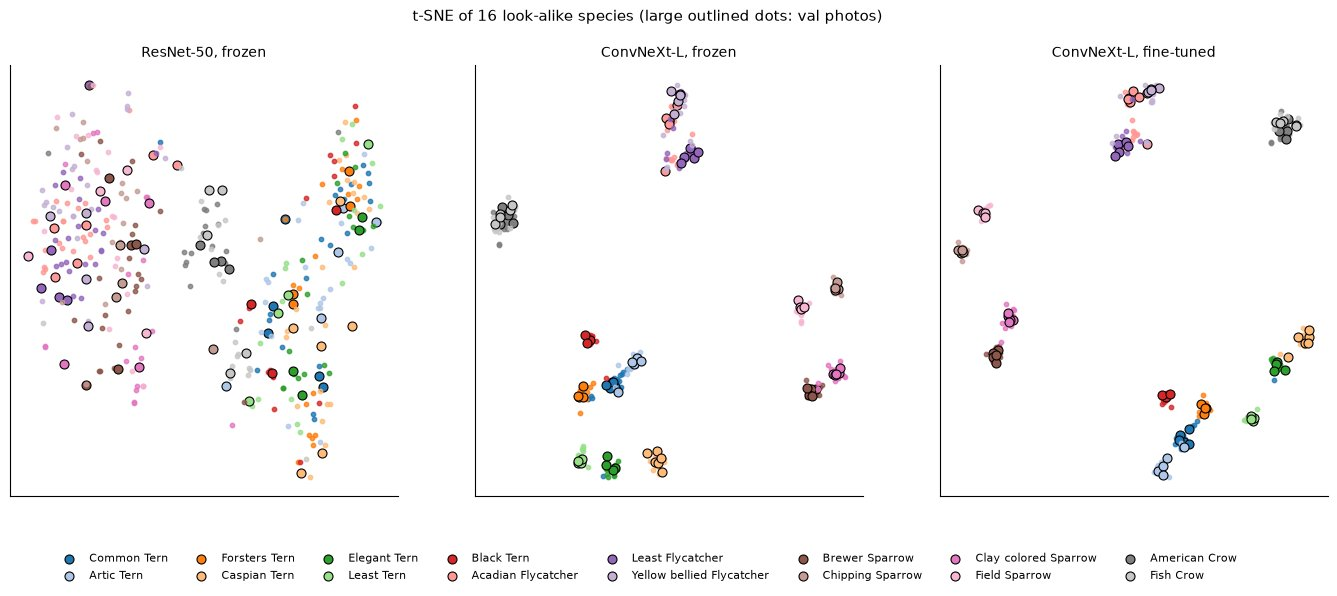

In [5]:
# Load fine-tuned embeddings
app = np.load(FEATURES / "app_embeddings.npz")
order = {f: i for i, f in enumerate(app["files"])}
train_files = np.array([s.filename for s in train])
train_y = np.array([s.label for s in train])
assert all(f in order for f in train_files)


def train_rows(d: dict) -> np.ndarray:
    """Flip-averaged frozen features of the training photos, in train.txt order."""
    row = {f: i for i, f in enumerate(d["files"])}
    return d["x"][[row[f] for f in train_files]].mean(axis=1)


# Collect the three embeddings
EMBEDDINGS = {
    "ResNet-50, frozen": train_rows(frozen["ResNet-50 (ImageNet-1k)"]),
    "ConvNeXt-L, frozen": train_rows(frozen["ConvNeXt-L (CLIP → iNat21)"]),
    "ConvNeXt-L, fine-tuned": app["embeddings"][[order[f] for f in train_files]],
}
is_val_photo = np.isin(train_files, list(val_names))

# Pick look-alike species
TSNE_SPECIES = ["Common Tern", "Artic Tern", "Forsters Tern", "Caspian Tern", "Elegant Tern", "Least Tern",
                "Black Tern", "Acadian Flycatcher", "Least Flycatcher", "Yellow bellied Flycatcher",
                "Brewer Sparrow", "Chipping Sparrow", "Clay colored Sparrow", "Field Sparrow", "American Crow",
                "Fish Crow"]
species_idx = [classes.index(n) for n in TSNE_SPECIES]
subset = np.isin(train_y, species_idx)

# Draw t-SNE of each embedding
colors = plt.get_cmap("tab20")(np.arange(len(species_idx)))
fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, (name, emb) in zip(axes, EMBEDDINGS.items()):
    xy = TSNE(n_components=2, perplexity=30, init="pca", metric="cosine", random_state=SEED).fit_transform(emb[subset])

    # Draw fit and val photos of each species
    for k, c in enumerate(species_idx):
        m = train_y[subset] == c
        v = is_val_photo[subset]
        ax.scatter(*xy[m & ~v].T, s=10, color=colors[k], alpha=0.8)
        ax.scatter(*xy[m & v].T, s=42, color=colors[k], edgecolors="black", linewidths=0.8,
                   label=classes[c] if ax is axes[0] else None)
    ax.set(title=name, xticks=[], yticks=[])
    ax.grid(False)

# Add legend and title
fig.legend(loc="lower center", ncol=8, fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("t-SNE of 16 look-alike species (large outlined dots: val photos)", fontsize=11)
show_jpeg(fig, quality=85)

Frozen ResNet-50 features sort the photos into two blobs, terns on one side and the small songbirds on the other, with the crows between them: a split by body plan and background (sky and water against foliage), not by species. Frozen ConvNeXt-L features already form one tight cluster per species. Fine-tuning tightens them a little more, and the val photos, which the network never trained on, land inside their species' cluster. Three groups stay merged in both ConvNeXt-L panels: American and Fish Crow form one cluster, the three Empidonax flycatchers share another, and Common and Arctic Tern touch. These are among the most frequent test confusions (section 9.6). t-SNE preserves neighborhoods, not distances, so only the grouping should be read from it, not the gaps between clusters.

### 7.5 Same species or not? Similarity distributions and k-NN accuracy

For every val photo and every fit photo, the cosine similarity of their embeddings. If an embedding separates species, pairs of the same species should be more similar than pairs of different species. The AUC below is the probability that a random same-species pair is more similar than a random different-species pair; k-NN accuracy classifies each val photo by its ten most similar fit photos. All 200 species are used.

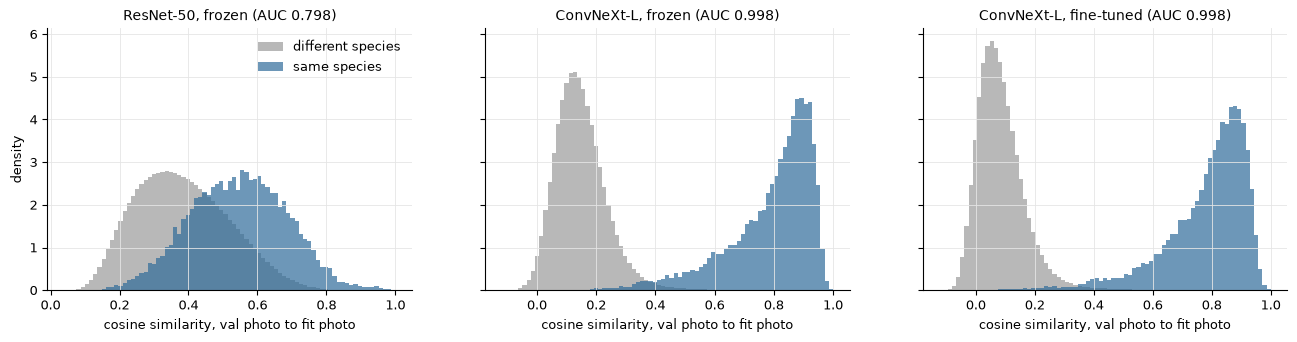

| embedding | same-vs-different AUC | k-NN val top-1 (k = 10) | nearest fit photo same species |
|---|---|---|---|
| ResNet-50, frozen | 0.798 | 39.1% | 37.2% |
| ConvNeXt-L, frozen | 0.998 | 97.3% | 97.2% |
| ConvNeXt-L, fine-tuned | 0.998 | 97.2% | 97.0% |

In [6]:
# Mark same-species pairs
fit_rows, val_rows = ~is_val_photo, is_val_photo
same = train_y[val_rows][:, None] == train_y[fit_rows][None, :]

# Draw similarity per embedding
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), sharey=True)
table = []
for ax, (name, emb) in zip(axes, EMBEDDINGS.items()):
    unit = emb / np.linalg.norm(emb, axis=1, keepdims=True)
    sims = unit[val_rows] @ unit[fit_rows].T

    # Score separation and nearest neighbors
    auc = roc_auc_score(same.ravel(), sims.ravel())
    knn = top1_accuracy(train_y[val_rows], knn_scores(emb[fit_rows], train_y[fit_rows], emb[val_rows], C).argmax(1))
    nearest_same = (train_y[fit_rows][sims.argmax(1)] == train_y[val_rows]).mean()
    table.append([name, f"{auc:.3f}", pct(knn), pct(nearest_same)])

    # Draw same and different species
    bins = np.linspace(sims.min(), sims.max(), 80)
    ax.hist(sims[~same], bins=bins, density=True, color=GRAY, alpha=0.7, label="different species")
    ax.hist(sims[same], bins=bins, density=True, color=BLUE, alpha=0.7, label="same species")
    ax.set(title=f"{name} (AUC {auc:.3f})", xlabel="cosine similarity, val photo to fit photo")

# Set labels and show
axes[0].set_ylabel("density")
axes[0].legend()
plt.show()

# Show table
md_table(["embedding", "same-vs-different AUC", "k-NN val top-1 (k = 10)", "nearest fit photo same species"], table)

For ResNet-50, same-species and different-species pairs overlap heavily (AUC 0.798), and a val photo's ten nearest fit photos give the right species only 39.1 % of the time. Frozen ConvNeXt-L separates them almost perfectly (AUC 0.998, k-NN 97.3 %). **Fine-tuning does not improve this** (AUC 0.998, k-NN 97.2 %). It pushes different-species pairs toward zero similarity but leaves the ranking of neighbors unchanged. This matches section 8.5: LP-FT with a small learning rate moves the backbone only a little. The 0.5 pp that fine-tuning adds on test comes from small adjustments, not from a re-organized feature space.

→ **Decision:** the web app shows the most similar training photos using the fine-tuned embedding. The nearest fit photo is the same species for 97.0 % of val photos, so the similar photos it shows are almost always the predicted species.

### 7.6 Nearest training photos

The five fit photos most similar to three val photos, under the frozen ResNet-50 and the frozen ConvNeXt-L. A green frame marks the right species, a red one a different species.

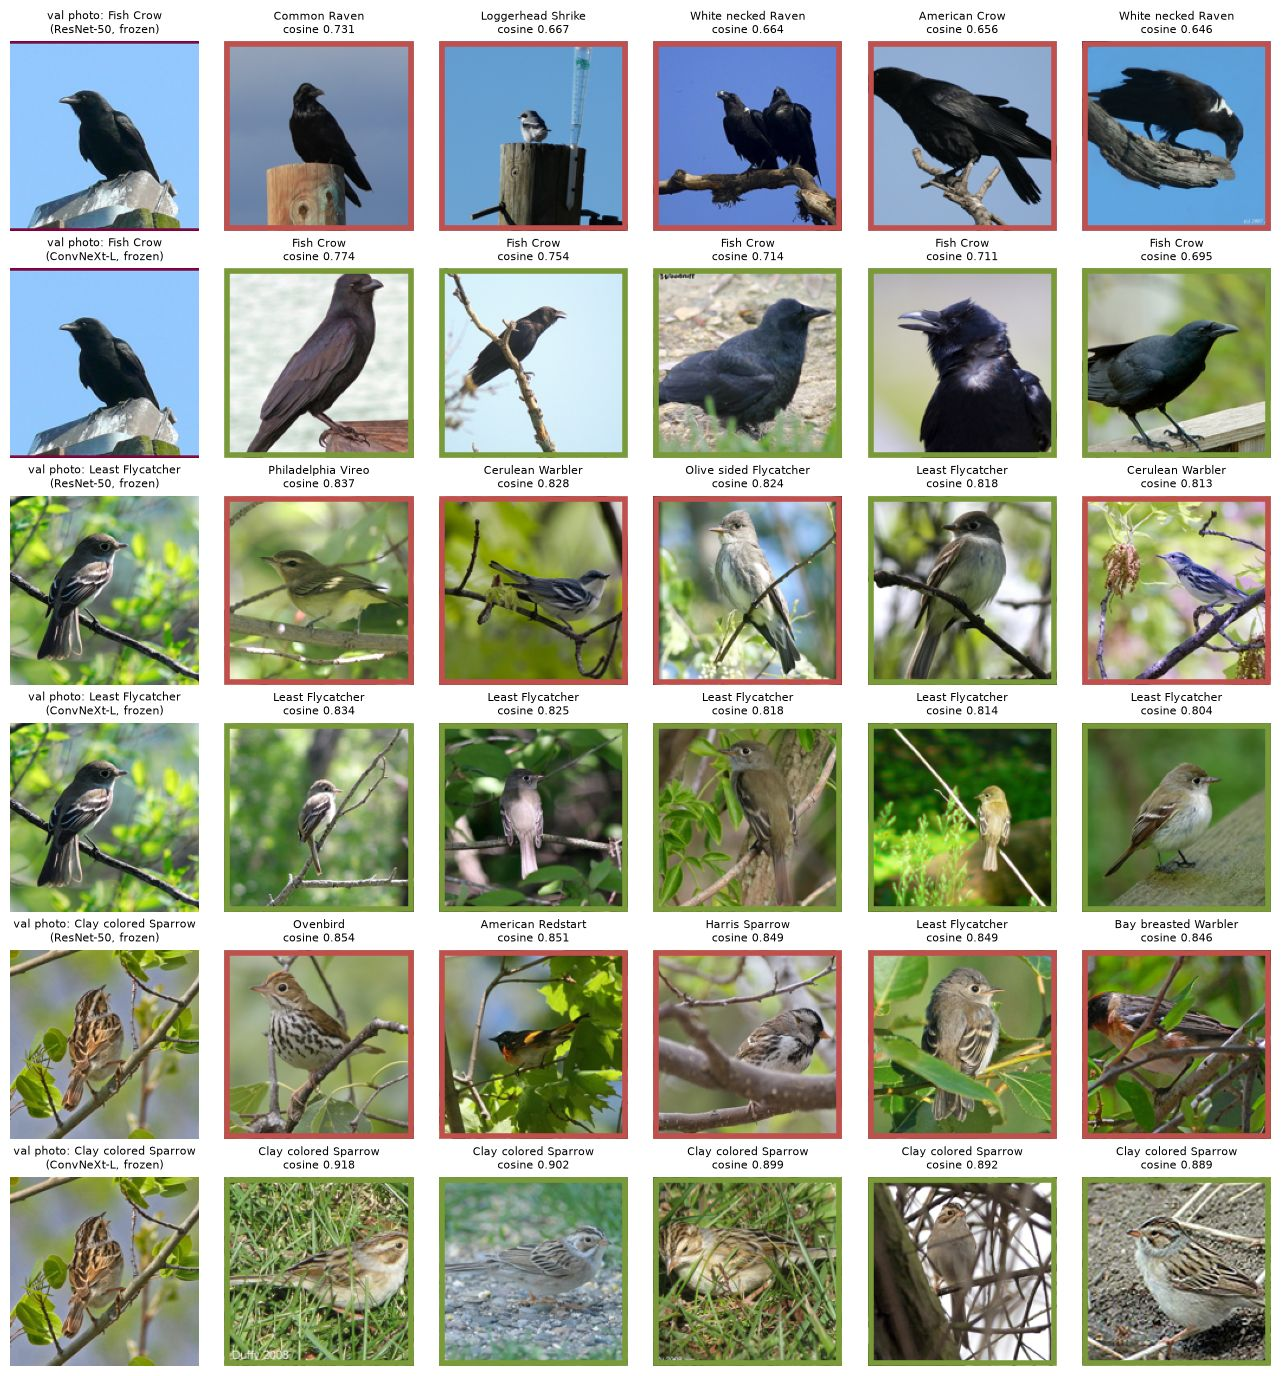

In [7]:
# Pick three val photos
queries = [next(i for i in np.flatnonzero(is_val_photo) if classes[train_y[i]] == n)
           for n in ("Fish Crow", "Least Flycatcher", "Clay colored Sparrow")]
fit_index = np.flatnonzero(fit_rows)

# Draw each photo's five nearest fit photos
fig, axes = plt.subplots(2 * len(queries), 6, figsize=(13, 4.6 * len(queries)))
for q, query in enumerate(queries):
    for r, name in enumerate(("ResNet-50, frozen", "ConvNeXt-L, frozen")):
        # Find the five nearest
        emb = EMBEDDINGS[name]
        unit = emb / np.linalg.norm(emb, axis=1, keepdims=True)
        sims = unit[fit_index] @ unit[query]
        best = fit_index[np.argsort(-sims)[:5]]

        # Draw the val photo
        row = axes[2 * q + r]
        row[0].imshow(square(DATA / "Train" / train_files[query], 160))
        row[0].set_title(f"val photo: {classes[train_y[query]]}\n({name})", fontsize=8)

        # Draw the neighbors, green if same species
        for ax, j in zip(row[1:], best):
            ax.imshow(square(DATA / "Train" / train_files[j], 160))
            color = GREEN if train_y[j] == train_y[query] else RED
            ax.add_patch(plt.Rectangle((2, 2), 155, 155, fill=False, edgecolor=color, linewidth=4))
            ax.set_title(f"{classes[train_y[j]]}\ncosine {unit[j] @ unit[query]:.3f}", fontsize=8)

        # Hide axes
        for ax in row:
            ax.axis("off")
fig.tight_layout()
show_jpeg(fig)

ResNet-50 matches the scene: the Fish Crow, a black bird on a post against blue sky, retrieves a Loggerhead Shrike on a post against blue sky; the Clay-colored Sparrow among green leaves retrieves an Ovenbird, an American Redstart, a Bay-breasted Warbler and two others among green leaves. It finds the right species for 1 of the 15 neighbors. ConvNeXt-L finds the right species for all 15, on varied backgrounds (grass, gravel, branches): it matches the bird, not the scene.

## 8. Training the final model

### 8.1 Learning curves

The training run logged one line per epoch (`metrics.jsonl`). The training loss and accuracy are measured on augmented, label-smoothed batches with drop-path active, so they cannot be compared with val directly. The run therefore also scores a fixed set of 922 fit photos exactly like val after every epoch (`train_eval`): the gap between that curve and val is the overfitting gap. Both the raw weights and their exponential moving average (EMA) are scored; the EMA weights are the ones kept.

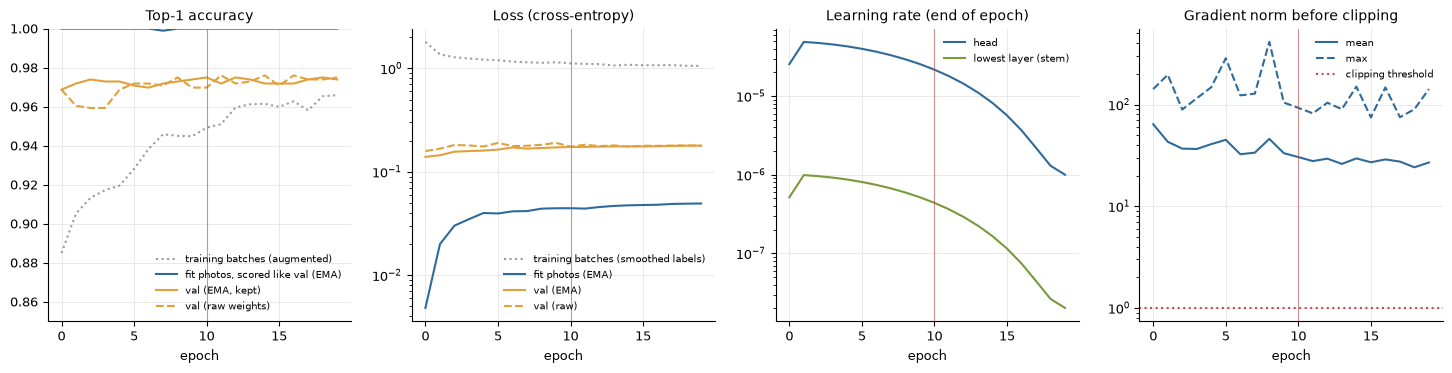

| epoch | train loss | train top-1 | fit top-1 (EMA) | val top-1 (EMA) | val top-1 (raw) | val NLL (EMA) | LR head | grad clipped | new best |
|---|---|---|---|---|---|---|---|---|---|
| 0 | 1.803 | 88.5% | 100.0% | 96.9% | 96.9% | 0.140 | 2.6e-05 | 100% | ✓ |
| 1 | 1.367 | 90.5% | 100.0% | 97.2% | 96.0% | 0.145 | 4.9e-05 | 100% | ✓ |
| 2 | 1.282 | 91.3% | 100.0% | 97.4% | 95.9% | 0.157 | 4.7e-05 | 100% | ✓ |
| 3 | 1.246 | 91.7% | 100.0% | 97.3% | 95.9% | 0.159 | 4.5e-05 | 100% |  |
| 4 | 1.216 | 92.0% | 100.0% | 97.3% | 96.9% | 0.160 | 4.3e-05 | 100% |  |
| 5 | 1.200 | 92.8% | 100.0% | 97.1% | 97.2% | 0.164 | 4.0e-05 | 100% |  |
| 6 | 1.162 | 93.8% | 100.0% | 97.0% | 97.2% | 0.172 | 3.7e-05 | 100% |  |
| 7 | 1.146 | 94.6% | 99.9% | 97.2% | 97.1% | 0.168 | 3.3e-05 | 100% |  |
| 8 | 1.132 | 94.5% | 100.0% | 97.3% | 97.5% | 0.170 | 2.9e-05 | 100% |  |
| 9 | 1.146 | 94.5% | 100.0% | 97.4% | 97.0% | 0.172 | 2.6e-05 | 100% |  |
| 10 | 1.120 | 94.9% | 100.0% | 97.5% | 97.0% | 0.174 | 2.2e-05 | 100% | ✓ |
| 11 | 1.104 | 95.1% | 100.0% | 97.2% | 97.6% | 0.174 | 1.8e-05 | 100% |  |
| 12 | 1.099 | 96.0% | 100.0% | 97.5% | 97.2% | 0.175 | 1.4e-05 | 100% |  |
| 13 | 1.066 | 96.1% | 100.0% | 97.4% | 97.3% | 0.176 | 1.1e-05 | 100% |  |
| 14 | 1.084 | 96.1% | 100.0% | 97.2% | 97.6% | 0.176 | 8.2e-06 | 100% |  |
| 15 | 1.074 | 96.0% | 100.0% | 97.2% | 97.1% | 0.176 | 5.7e-06 | 100% |  |
| 16 | 1.072 | 96.3% | 100.0% | 97.2% | 97.6% | 0.177 | 3.7e-06 | 100% |  |
| 17 | 1.075 | 95.8% | 100.0% | 97.4% | 97.4% | 0.178 | 2.2e-06 | 100% |  |
| 18 | 1.060 | 96.5% | 100.0% | 97.5% | 97.4% | 0.179 | 1.3e-06 | 100% |  |
| 19 | 1.056 | 96.6% | 100.0% | 97.4% | 97.5% | 0.179 | 1.0e-06 | 100% |  |

In [8]:
# Load the epoch log
log = [r for r in read_jsonl(RUN_LOGS / FINAL / "metrics.jsonl") if "epoch" in r]
epoch = np.array([r["epoch"] for r in log])
best = summary["best_epoch"]


# Get one logged value per epoch
def series(key: str, rows: list[dict] = log) -> np.ndarray:
    return np.array([r[key] for r in rows], dtype=float)


# Draw training curves
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))

# Draw accuracy
for key, color, style, label in (("train_top1", GRAY, ":", "training batches (augmented)"),
                                  ("ema_train_eval_top1", BLUE, "-", "fit photos, scored like val (EMA)"),
                                  ("ema_val_top1", ORANGE, "-", "val (EMA, kept)"),
                                  ("val_top1", ORANGE, "--", "val (raw weights)")):
    axes[0].plot(epoch, series(key), style, color=color, label=label)
axes[0].set(title="Top-1 accuracy", ylim=(0.85, 1.0))

# Draw loss
for key, color, style, label in (("train_loss", GRAY, ":", "training batches (smoothed labels)"),
                                  ("ema_train_eval_loss", BLUE, "-", "fit photos (EMA)"),
                                  ("ema_val_loss", ORANGE, "-", "val (EMA)"),
                                  ("val_loss", ORANGE, "--", "val (raw)")):
    axes[1].plot(epoch, series(key), style, color=color, label=label)
axes[1].set(title="Loss (cross-entropy)", yscale="log")

# Draw learning rate
axes[2].plot(epoch, series("lr_head"), color=BLUE, label="head")
axes[2].plot(epoch, series("lr_min"), color=GREEN, label="lowest layer (stem)")
axes[2].set(title="Learning rate (end of epoch)", yscale="log")

# Draw gradient norm
axes[3].plot(epoch, series("grad_norm_mean"), color=BLUE, label="mean")
axes[3].plot(epoch, series("grad_norm_max"), color=BLUE, linestyle="--", label="max")
axes[3].axhline(1.0, color=RED, linestyle=":", label="clipping threshold")
axes[3].set(title="Gradient norm before clipping", yscale="log")

# Mark the kept epoch and add legends
for ax in axes:
    ax.axvline(best, color=RED, linewidth=0.8, alpha=0.6)
    ax.set_xlabel("epoch")
    ax.legend(fontsize=7.5)
plt.show()

# Show the epoch table
md_table(["epoch", "train loss", "train top-1", "fit top-1 (EMA)", "val top-1 (EMA)", "val top-1 (raw)",
          "val NLL (EMA)", "LR head", "grad clipped", "new best"], [
    [r["epoch"], f"{r['train_loss']:.3f}", pct(r["train_top1"]), pct(r["ema_train_eval_top1"]),
     pct(r["ema_val_top1"]), pct(r["val_top1"]), f"{r['ema_val_loss']:.3f}", f"{r['lr_head']:.1e}",
     pct(r["clipped_frac"], 0), "✓" if r["new_best"] else ""] for r in log])

The run starts from the linear probe's head (LP-FT), so after the very first epoch val accuracy is already 96.9 % and the fit photos are at 100 %. Over 20 epochs the EMA val accuracy moves only between 96.9 % and 97.5 %; it peaks at epoch 10 (kept), and later epochs match but do not beat it. The raw weights dip to 95.9 % at epochs 2–3, when the learning rate peaks after warm-up, while the EMA weights do not dip. Accuracy on the augmented training batches rises from 88.5 % to 96.6 % as the network adapts to the augmentations, while a fixed subset of 922 fit photos, scored without augmentation, stays at 99.9–100 % throughout.

Val loss rises from 0.140 to 0.179 while val accuracy stays flat, and the fit photos' loss rises from 0.005 to 0.05. That is not overfitting. Label smoothing (0.1) trains the network to spread about 10 % of the probability over the other classes, so it becomes **less** confident on photos it gets right. This under-confidence is what the temperature of 0.73 removes (section 9.8). The gradient norm before clipping averages 25–65 per epoch, peaks near 400, and exceeds the threshold of 1.0 in every update, so every update is clipped. Clipping at 1.0 therefore acts as gradient normalization: the learning rate alone sets the step size.

→ **Decision:** the EMA weights of epoch 10 are the final model. Twenty epochs were more than needed, but the flat val curve shows that the extra epochs cost nothing in accuracy.

### 8.2 Every optimizer update

`steps.jsonl` holds one line per optimizer update: 60 updates per epoch (3,870 photos in effective batches of 64), 1,200 in all.

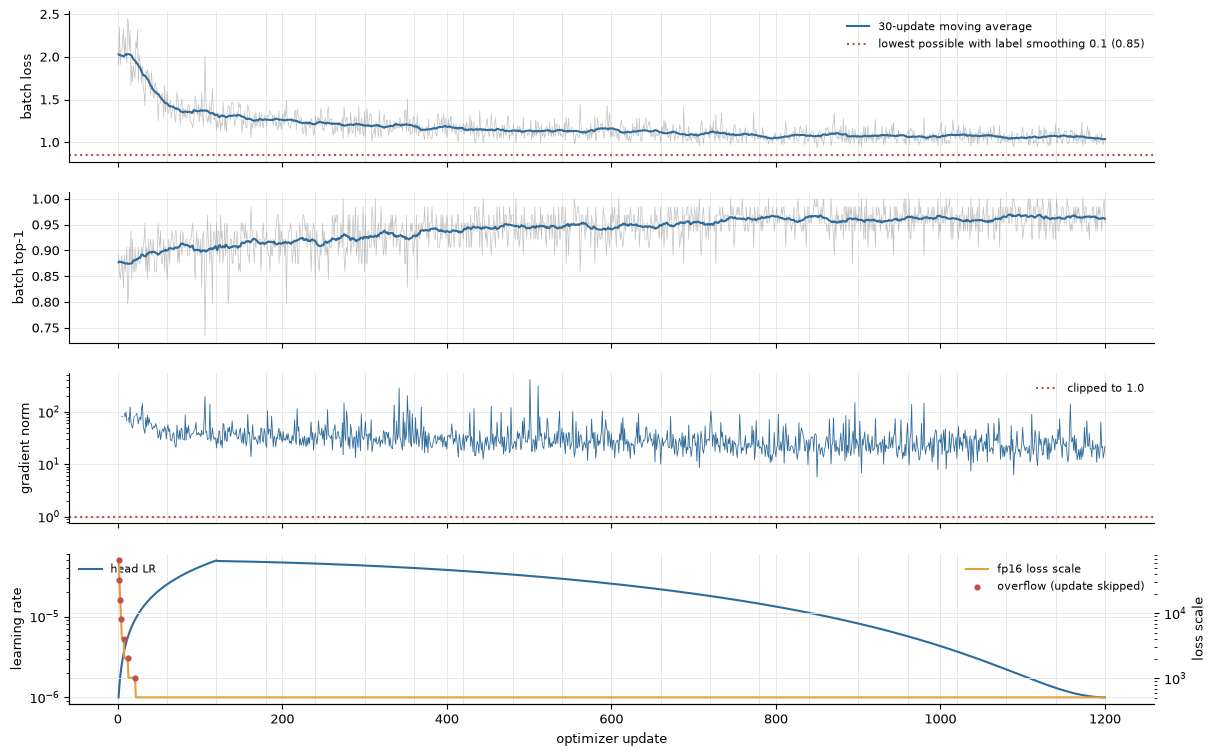

1200 updates; 7 fp16 overflows (skipped); 100% of updates had a gradient norm above the clipping threshold


In [9]:
# Load the step log
steps = read_jsonl(RUN_LOGS / FINAL / "steps.jsonl")
update = series("update", steps)


# Smooth with a moving average
def smooth(values: np.ndarray, window: int = 30) -> np.ndarray:
    kernel = np.ones(window) / window
    return np.convolve(np.pad(values, (window // 2, window - 1 - window // 2), mode="edge"), kernel, mode="valid")


# Draw per-update curves
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
loss, top1 = series("loss", steps), series("top1", steps)

# Draw loss
axes[0].plot(update, loss, color=GRAY, linewidth=0.5, alpha=0.6)
axes[0].plot(update, smooth(loss), color=BLUE, label="30-update moving average")
# Even a perfect prediction leaves this much loss: the entropy of the label-smoothed target.
smoothing = json.loads((RUN_LOGS / FINAL / "config.json").read_text())["label_smoothing"]
target = np.full(C, smoothing / C)
target[0] += 1 - smoothing
loss_floor = float(-(target * np.log(target)).sum())
axes[0].axhline(loss_floor, color=RED, linestyle=":", label=f"lowest possible with label smoothing {smoothing} ({loss_floor:.2f})")
axes[0].set(ylabel="batch loss")

# Draw batch accuracy
axes[1].plot(update, top1, color=GRAY, linewidth=0.5, alpha=0.6)
axes[1].plot(update, smooth(top1), color=BLUE)
axes[1].set(ylabel="batch top-1")

# Draw gradient norm
grad = np.array([np.nan if s["grad_norm"] is None else s["grad_norm"] for s in steps])
axes[2].plot(update, grad, color=BLUE, linewidth=0.6)
axes[2].axhline(1.0, color=RED, linestyle=":", label="clipped to 1.0")
axes[2].set(ylabel="gradient norm", yscale="log")

# Draw learning rate and loss scale
axes[3].plot(update, series("lr_head", steps), color=BLUE, label="head LR")
ax_scale = axes[3].twinx()
ax_scale.plot(update, series("loss_scale", steps), color=ORANGE, label="fp16 loss scale")
overflow = [s for s in steps if s["overflow"]]
ax_scale.scatter([s["update"] for s in overflow], [s["loss_scale"] for s in overflow], color=RED, s=12, zorder=3,
                 label="overflow (update skipped)")
ax_scale.set(yscale="log", ylabel="loss scale")
axes[3].set(ylabel="learning rate", yscale="log", xlabel="optimizer update")

# Add legends and epoch lines
for ax in (axes[0], axes[2]):
    ax.legend(loc="upper right", fontsize=8)
axes[3].legend(loc="upper left", fontsize=8)
ax_scale.legend(loc="upper right", fontsize=8)
for e in range(0, len(steps) + 1, 60):
    for ax in axes:
        ax.axvline(e, color="#dddddd", linewidth=0.5, zorder=0)
plt.show()

# Print summary
print(f"{len(steps)} updates; {len(overflow)} fp16 overflows (skipped); "
      f"{np.mean(grad[~np.isnan(grad)] > 1.0):.0%} of updates had a gradient norm above the clipping threshold")

The batch loss falls fast during the two warm-up epochs (120 updates), then slowly to about 1.05. It cannot fall much further: even a perfect prediction leaves the entropy of the smoothed target, the red dotted line. The fp16 loss scale starts at 65,536 and halves on each of the first 7 overflows, skipping those 7 updates (0.6 % of the run, all at the start of warm-up, when the learning rate is tiny). It then stays at 512, because PyTorch's gradient scaler only doubles it after 2,000 updates without an overflow, more than the run's 1,200.

### 8.3 Overfitting: ResNet-50 against ConvNeXt-L

The same recipe applied to the ResNet-50 baseline, with a cosine and with a plateau learning-rate schedule. The gap is the fit photos' score minus val's, both under EMA weights and both scored without augmentation.

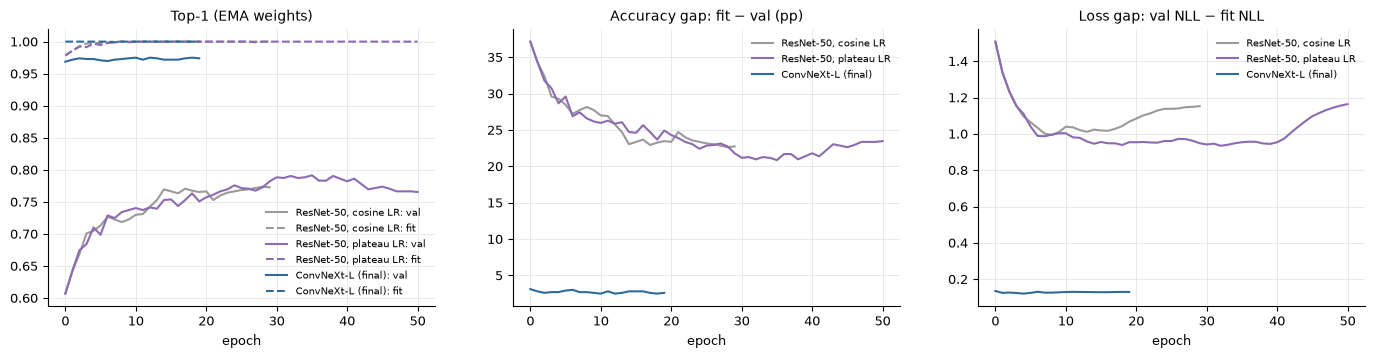

| run | kept epoch | fit top-1 | val top-1 | accuracy gap | NLL gap | test top-1 |
|---|---|---|---|---|---|---|
| ResNet-50, cosine LR | 28 | 100.0% | 77.4% | 22.6 pp | 1.149 | 74.7% |
| ResNet-50, plateau LR | 35 | 100.0% | 79.1% | 20.9 pp | 0.954 | 77.9% |
| ConvNeXt-L (final) | 10 | 100.0% | 97.5% | 2.5 pp | 0.129 | 96.6% |

In [10]:
# Pick runs to compare
RUNS_COMPARED = {"ResNet-50, cosine LR": "resnet50_448", "ResNet-50, plateau LR": "resnet50_448_plateau",
                 "ConvNeXt-L (final)": FINAL}

# Draw accuracy and loss gaps per run
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
table = []
for (name, run), color in zip(RUNS_COMPARED.items(), (GRAY, PURPLE, BLUE)):
    # Load the run
    rows = [r for r in read_jsonl(RUN_LOGS / run / "metrics.jsonl") if "epoch" in r]
    run_summary = json.loads((RUN_LOGS / run / "summary.json").read_text())
    e = series("epoch", rows)

    # Draw curves
    axes[0].plot(e, series("ema_val_top1", rows), color=color, label=f"{name}: val")
    axes[0].plot(e, series("ema_train_eval_top1", rows), color=color, linestyle="--", label=f"{name}: fit")
    axes[1].plot(e, 100 * (series("ema_train_eval_top1", rows) - series("ema_val_top1", rows)), color=color,
                 label=name)
    axes[2].plot(e, series("ema_val_loss", rows) - series("ema_train_eval_loss", rows), color=color, label=name)

    # Collect table row
    at_best = next(r for r in rows if r["epoch"] == run_summary["best_epoch"])
    table.append([name, run_summary["best_epoch"], pct(at_best["ema_train_eval_top1"]), pct(at_best["ema_val_top1"]),
                  f"{100 * (at_best['ema_train_eval_top1'] - at_best['ema_val_top1']):.1f} pp",
                  f"{at_best['ema_val_loss'] - at_best['ema_train_eval_loss']:.3f}", pct(run_summary["test"]["top1"])])

# Set titles and show
axes[0].set(title="Top-1 (EMA weights)", xlabel="epoch")
axes[1].set(title="Accuracy gap: fit − val (pp)", xlabel="epoch")
axes[2].set(title="Loss gap: val NLL − fit NLL", xlabel="epoch")
for ax in axes:
    ax.legend(fontsize=7.5)
plt.show()

# Show table
md_table(["run", "kept epoch", "fit top-1", "val top-1", "accuracy gap", "NLL gap", "test top-1"], table)

ResNet-50 fits every fit photo within about ten epochs, while val climbs slowly to 77–79 %, a gap of 21–23 pp. Its loss gap grows again late in training (after epoch 15 with the cosine schedule, after epoch 40 with the plateau schedule): it keeps getting more confident on photos it has memorized. ConvNeXt-L, trained with the same recipe on the same photos, has a gap of 2.5 pp that stays flat from the first epoch. The difference is the starting point: a probe on frozen ResNet-50 features reaches only 65 % (section 7.1), so the ResNet must learn the species from about 19 photos each, and it memorizes them instead.

→ **Decision:** ResNet-50 stays as the baseline the brief requires. Its overfitting is not a recipe problem: neither stronger nor weaker regularization closes the gap (section 8.6).

### 8.4 Layer-wise learning-rate decay

`build_optimizer` gives the classifier head the full learning rate and every layer below it 0.9 times the rate of the layer above, so the early layers, which hold generic edge and texture detectors, change least. The cell builds the network without its weights (only the architecture is needed) and reads the learning-rate scale of every parameter group out of the optimizer.

198.9 M parameters in 76 parameter groups and 38 learning-rate levels, from 1.01e-06 to 5.00e-05 (the run logged at most 9.89e-07 for its lowest layer, at the end of the warm-up epoch)


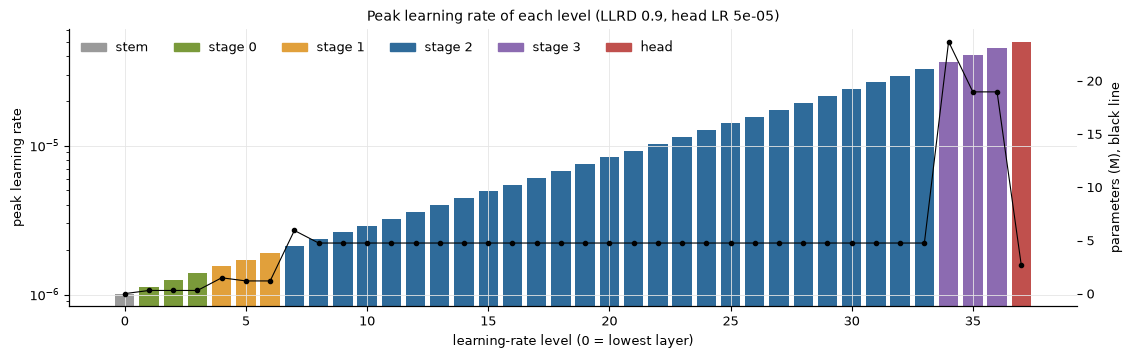

| part of the network | parameters (M) | learning-rate levels | peak learning rate |
|---|---|---|---|
| stem | 0.0 | 1 | 1.0e-06 – 1.0e-06 |
| stage 0 | 0.9 | 3 | 1.1e-06 – 1.4e-06 |
| stage 1 | 3.9 | 3 | 1.5e-06 – 1.9e-06 |
| stage 2 | 129.8 | 27 | 2.1e-06 – 3.3e-05 |
| stage 3 | 61.6 | 3 | 3.6e-05 – 4.5e-05 |
| head | 2.7 | 1 | 5.0e-05 – 5.0e-05 |

In [11]:
# Build the model and optimizer
cfg = TrainConfig(**json.loads((RUN_LOGS / FINAL / "config.json").read_text()))
cfg.pretrained, cfg.head_init, cfg.grad_checkpointing = False, "", False
# The backbone's hub config is copied into the app bundle, so the architecture builds offline.
model, data_cfg = build_model(cfg, f"local-dir:{BUNDLE / 'base_model'}")
optimizer = build_optimizer(model, cfg)
name_of = {id(p): n for n, p in model.named_parameters()}


# Name the part of the network a parameter belongs to
def part(name: str) -> str:
    bits = name.split(".")
    return f"stage {bits[1]}" if bits[0] == "stages" else bits[0]


# Count parameters per learning-rate level and part
levels = defaultdict(Counter)  # learning-rate scale -> parameters per part of the network
parts = defaultdict(lambda: [0, set()])  # part -> parameter count, learning rates
for g in optimizer.param_groups:
    scale = g.get("lr_scale", 1.0)
    for p in g["params"]:
        where = part(name_of[id(p)])
        levels[scale][where] += p.numel()
        parts[where][0] += p.numel()
        parts[where][1].add(cfg.lr * scale)

# Print summary
scales = sorted(levels)
n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params / 1e6:.1f} M parameters in {len(optimizer.param_groups)} parameter groups and {len(scales)} "
      f"learning-rate levels, from {cfg.lr * scales[0]:.2e} to {cfg.lr * scales[-1]:.2e} "
      f"(the run logged at most {max(series('lr_min')):.2e} for its lowest layer, at the end of the warm-up epoch)")

# Draw peak learning rate per level
part_color = dict(zip(sorted(parts, key=lambda p: min(parts[p][1])), (GRAY, GREEN, ORANGE, BLUE, PURPLE, RED, "black")))
fig, ax1 = plt.subplots(figsize=(13, 3.6))
for depth, scale in enumerate(scales):
    ax1.bar(depth, cfg.lr * scale, color=part_color[levels[scale].most_common(1)[0][0]])
ax1.set(yscale="log", xlabel="learning-rate level (0 = lowest layer)", ylabel="peak learning rate",
        title=f"Peak learning rate of each level (LLRD {cfg.layer_decay}, head LR {cfg.lr:g})")

# Draw parameters per level
ax2 = ax1.twinx()
ax2.plot(range(len(scales)), [sum(levels[s].values()) / 1e6 for s in scales], "k.-", linewidth=0.8)
ax2.set_ylabel("parameters (M), black line")
ax2.grid(False)

# Add legend and show
ax1.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in part_color.values()], part_color.keys(), ncol=7,
           loc="upper left")
plt.show()

# Show table
md_table(["part of the network", "parameters (M)", "learning-rate levels", "peak learning rate"],
         [[p, f"{parts[p][0] / 1e6:.1f}", len(parts[p][1]), f"{min(parts[p][1]):.1e} – {max(parts[p][1]):.1e}"]
          for p in part_color])

ConvNeXt-L has 38 learning-rate levels: the stem, one level per block (3, 3, 27 and 3 blocks in its four stages) and the head. With a decay of 0.9 per level, the stem trains at 0.9³⁷ ≈ 2 % of the head's rate (1.0 × 10⁻⁶ against 5 × 10⁻⁵). Stage 2 holds 130 M of the 199 M parameters and spans most of the range. The early stages, with their generic edge and texture detectors, barely move. The last stage, with the most task-specific features, trains at 72–90 % of the head's rate.

### 8.5 Why LP-FT and LLRD matter: how far the weights move

Every run logged how far its weights had moved from where they started, the backbone and the classifier head separately (Euclidean distance over all parameters). Three runs of the final recipe with different seeds are compared with the two ablation runs that hurt most: a randomly initialized head instead of the linear-probe head (no LP-FT), and one learning rate for all layers (no LLRD).

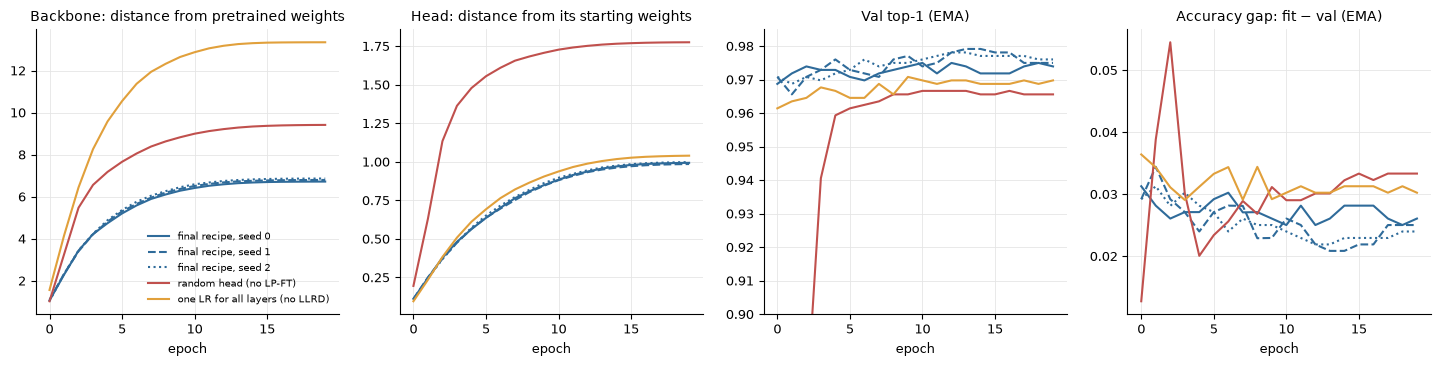

| run | backbone moved after epoch 0 | after the last epoch | head moved | val top-1 after epoch 0 | val top-1 (kept) | test top-1 |
|---|---|---|---|---|---|---|
| final recipe, seed 0 | 1.06 | 6.72 | 0.99 | 96.9% | 97.5% | 96.6% |
| final recipe, seed 1 | 1.09 | 6.79 | 0.99 | 97.1% | 97.9% | 96.2% |
| final recipe, seed 2 | 1.03 | 6.86 | 1.00 | 97.1% | 97.8% | 95.9% |
| random head (no LP-FT) | 1.02 | 9.41 | 1.78 | 4.7% | 96.7% | 96.1% |
| one LR for all layers (no LLRD) | 1.56 | 13.35 | 1.04 | 96.1% | 97.1% | 95.6% |

In [12]:
# Pick runs to compare
DRIFT_RUNS = {"final recipe, seed 0": FINAL, "final recipe, seed 1": "abl_convnext__control__s1",
              "final recipe, seed 2": "abl_convnext__control__s2", "random head (no LP-FT)": "abl_convnext__no_lpft__s0",
              "one LR for all layers (no LLRD)": "abl_convnext__no_llrd__s0"}
style = {FINAL: (BLUE, "-"), "abl_convnext__control__s1": (BLUE, "--"), "abl_convnext__control__s2": (BLUE, ":"),
         "abl_convnext__no_lpft__s0": (RED, "-"), "abl_convnext__no_llrd__s0": (ORANGE, "-")}

# Draw weight drift per run
fig, axes = plt.subplots(1, 4, figsize=(18, 3.7))
table = []
for name, run in DRIFT_RUNS.items():
    # Load the run
    rows = [r for r in read_jsonl(RUN_LOGS / run / "metrics.jsonl") if "epoch" in r]
    color, line = style[run]
    e = series("epoch", rows)

    # Draw distances, accuracy and gap
    axes[0].plot(e, series("dist_from_init", rows), color=color, linestyle=line, label=name)
    axes[1].plot(e, series("head_dist_from_init", rows), color=color, linestyle=line, label=name)
    axes[2].plot(e, series("ema_val_top1", rows), color=color, linestyle=line, label=name)
    axes[3].plot(e, series("ema_train_eval_top1", rows) - series("ema_val_top1", rows), color=color, linestyle=line,
                 label=name)

    # Collect table row
    run_summary = json.loads((RUN_LOGS / run / "summary.json").read_text())
    table.append([name, f"{rows[0]['dist_from_init']:.2f}", f"{rows[-1]['dist_from_init']:.2f}",
                  f"{rows[-1]['head_dist_from_init']:.2f}", pct(rows[0]["ema_val_top1"]), pct(run_summary["val"]["top1"]),
                  pct(run_summary["test"]["top1"])])

# Set titles and show
axes[0].set(title="Backbone: distance from pretrained weights", xlabel="epoch")
axes[1].set(title="Head: distance from its starting weights", xlabel="epoch")
axes[2].set(title="Val top-1 (EMA)", xlabel="epoch", ylim=(0.90, 0.985))
axes[3].set(title="Accuracy gap: fit − val (EMA)", xlabel="epoch")
axes[0].legend(fontsize=7.5)
plt.show()

# Show table
md_table(["run", "backbone moved after epoch 0", "after the last epoch", "head moved", "val top-1 after epoch 0",
          "val top-1 (kept)", "test top-1"], table)

With the final recipe, the backbone moves 1.0 in the first epoch and about 6.8 by the end, and the three seeds trace almost the same curve. **Without LP-FT**, the randomly initialized head is useless at first (4.7 % val after epoch 0). Its large errors flow back into the backbone, which ends 40 % further from its pretrained weights (9.4), and val stays 1.1 pp below the recipe's mean. This is the feature distortion that LP-FT is designed to avoid (Kumar et al., 2022). **Without LLRD**, the backbone moves twice as far (13.4), and val (97.1 %) and test (95.6 %) both drop. Moving the pretrained features further costs accuracy in both cases, which agrees with section 7.5: the frozen features are already close to ideal for this task.

### 8.6 The ablation study

Each ablation run changes one thing in the final recipe and trains once (seed 0). The recipe itself was trained with three seeds; their spread σ of val accuracy is the noise yardstick, and only changes well beyond 2σ mean anything. Test accuracy is shown but was never used to choose anything. `scripts/ablation_report.py` wrote `results/ablation.csv`; McNemar's test compares each run's per-photo correctness with seed 0 of the recipe.

ConvNeXt-L ablation: one change at a time: control val 97.74% ± 0.22 pp (σ over 3 seeds), test 96.23%


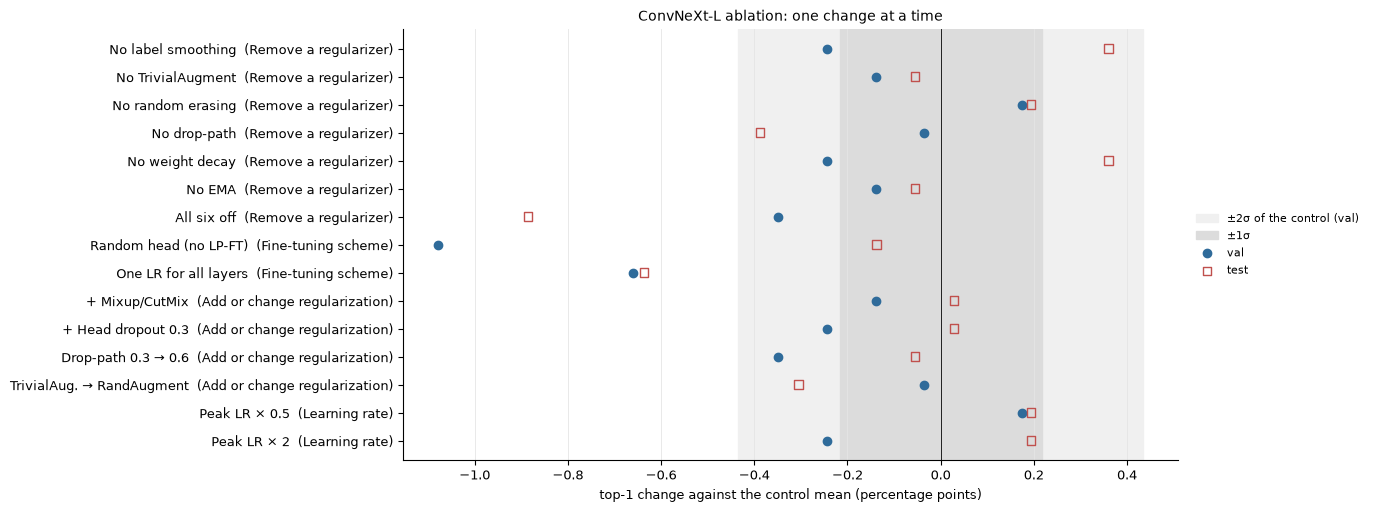

| change | val top-1 | Δ val | Δ val / σ | test top-1 | Δ test | McNemar p (val) | McNemar p (test) | fit − val gap |
|---|---|---|---|---|---|---|---|---|
| No label smoothing | 97.50% | -0.24 pp | -1.1 | 96.59% | +0.36 pp | 1.000 | 1.000 | 2.5 pp |
| No TrivialAugment | 97.60% | -0.14 pp | -0.6 | 96.18% | -0.06 pp | 1.000 | 0.383 | 2.3 pp |
| No random erasing | 97.91% | +0.17 pp | +0.8 | 96.43% | +0.19 pp | 0.289 | 0.804 | 2.1 pp |
| No drop-path | 97.71% | -0.03 pp | -0.2 | 95.85% | -0.39 pp | 0.754 | 0.064 | 2.3 pp |
| No weight decay | 97.50% | -0.24 pp | -1.1 | 96.59% | +0.36 pp | 1.000 | 1.000 | 2.5 pp |
| No EMA | 97.60% | -0.14 pp | -0.6 | 96.18% | -0.06 pp | 1.000 | 0.180 | 2.4 pp |
| All six off | 97.39% | -0.35 pp | -1.6 | 95.35% | -0.89 pp | 1.000 | 0.004 | 2.6 pp |
| Random head (no LP-FT) | 96.66% | -1.08 pp | -5.0 | 96.10% | -0.14 pp | 0.115 | 0.362 | 2.9 pp |
| One LR for all layers | 97.08% | -0.66 pp | -3.0 | 95.60% | -0.64 pp | 0.424 | 0.029 | 2.9 pp |
| + Mixup/CutMix | 97.60% | -0.14 pp | -0.6 | 96.26% | +0.03 pp | 1.000 | 0.455 | 2.4 pp |
| + Head dropout 0.3 | 97.50% | -0.24 pp | -1.1 | 96.26% | +0.03 pp | 1.000 | 0.424 | 2.5 pp |
| Drop-path 0.3 → 0.6 | 97.39% | -0.35 pp | -1.6 | 96.18% | -0.06 pp | 1.000 | 0.332 | 2.5 pp |
| TrivialAug. → RandAugment | 97.71% | -0.03 pp | -0.2 | 95.93% | -0.30 pp | 0.754 | 0.077 | 2.3 pp |
| Peak LR × 0.5 | 97.91% | +0.17 pp | +0.8 | 96.43% | +0.19 pp | 0.219 | 0.727 | 2.1 pp |
| Peak LR × 2 | 97.50% | -0.24 pp | -1.1 | 96.43% | +0.19 pp | 1.000 | 0.774 | 2.5 pp |

In [13]:
# Draw and tabulate an ablation
def ablation(path: Path, title: str, height: float) -> None:
    # Load results
    rows = read_csv(path)
    sd = float(rows[0]["control_val_sd"])
    variants = ra.by_group(rows)
    controls = [r for r in rows if r["variant"] == "control"]

    # Print the control
    print(f"{title}: control val {pct(np.mean([float(r['val_top1']) for r in controls]), 2)} "
          f"± {100 * sd:.2f} pp (σ over {len(controls)} seeds), test {pct(np.mean([float(r['test_top1']) for r in controls]), 2)}")

    # Draw seed-noise bands
    _, ax = plt.subplots(figsize=(10, height))
    ax.axvspan(-200 * sd, 200 * sd, color="#f0f0f0", label="±2σ of the control (val)")
    ax.axvspan(-100 * sd, 100 * sd, color="#dcdcdc", label="±1σ")
    ax.axvline(0, color="black", linewidth=0.6)

    # Draw val and test changes
    yy = np.arange(len(variants))[::-1]
    ax.scatter([100 * float(r["dval"]) for r in variants], yy, color=BLUE, s=36, zorder=3, label="val")
    ax.scatter([100 * float(r["dtest"]) for r in variants], yy, facecolors="none", edgecolors=RED, marker="s", s=36,
               zorder=3, label="test")

    # Set labels and show
    ax.set_yticks(yy, [f"{ra.VARIANTS[r['variant']]}  ({ra.GROUPS[r['group']]})" for r in variants])
    ax.set(xlabel="top-1 change against the control mean (percentage points)", title=title)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
    plt.show()

    # Show table
    md_table(["change", "val top-1", "Δ val", "Δ val / σ", "test top-1", "Δ test", "McNemar p (val)",
              "McNemar p (test)", "fit − val gap"], [
        [ra.VARIANTS[r["variant"]], pct(float(r["val_top1"]), 2), f"{100 * float(r['dval']):+.2f} pp",
         f"{float(r['dval_sd']):+.1f}", pct(float(r["test_top1"]), 2), f"{100 * float(r['dtest']):+.2f} pp",
         f"{float(r['val_mcnemar_p']):.3f}", f"{float(r['test_mcnemar_p']):.3f}",
         f"{100 * float(r['gap_top1_at_best']):.1f} pp"] for r in variants])


# Draw the ConvNeXt-L ablation
ablation(RESULTS / "ablation.csv", "ConvNeXt-L ablation: one change at a time", 5.6)

The three seeds of the unchanged recipe already span 97.5–97.9 % val and 95.9–96.6 % test, so differences below about 0.4 pp (2σ) are indistinguishable from a change of seed. Measured against that:
- **Only two changes are clearly worse on val**: a random head instead of LP-FT (−5.0σ) and one learning rate for all layers (−3.0σ). The second is also worse on test (−0.64 pp, McNemar p = 0.029). For the first, test barely moves (−0.14 pp), so its evidence rests on val alone.
- **Each regularizer alone is redundant**: removing any one changes val by at most 1.1σ. Removing all six together costs −1.6σ on val and −0.9 pp on test (McNemar p = 0.004 on test), so they matter as a group, each covering for the others.
- **Without weight decay, the predictions are identical to seed 0 of the recipe**, photo for photo (McNemar 0 against 0). The decay was applied, but AdamW shrinks each weight by the learning rate times the decay per update, and at learning rates of at most 5 × 10⁻⁵ a decay of 0.05 changes the final parameter norm by only 0.02 % (723.83 with decay, 723.96 without), too little to change any prediction. Without label smoothing, the accuracy also matches seed 0, but different photos are right (5 against 5 on val).
- **Additions and other changes** (Mixup/CutMix, head dropout 0.3, drop-path 0.6, RandAugment instead of TrivialAugment, half or double the peak learning rate) all stay within 1.6σ. The recipe sits on a plateau where these choices do not matter.

→ **Decision:** LP-FT and LLRD are kept, since they are the only changes with evidence. The six regularizers are kept together, as removing them all costs accuracy and keeping them costs nothing measurable. Half the learning rate and no random erasing scored best on val (+0.8σ each), but within noise, so the original recipe stayed.

The same exercise on the ResNet-50 baseline, whose problem is the opposite one: it overfits (section 8.3).

ResNet-50 ablation: control val 76.71% ± 0.71 pp (σ over 3 seeds), test 73.86%


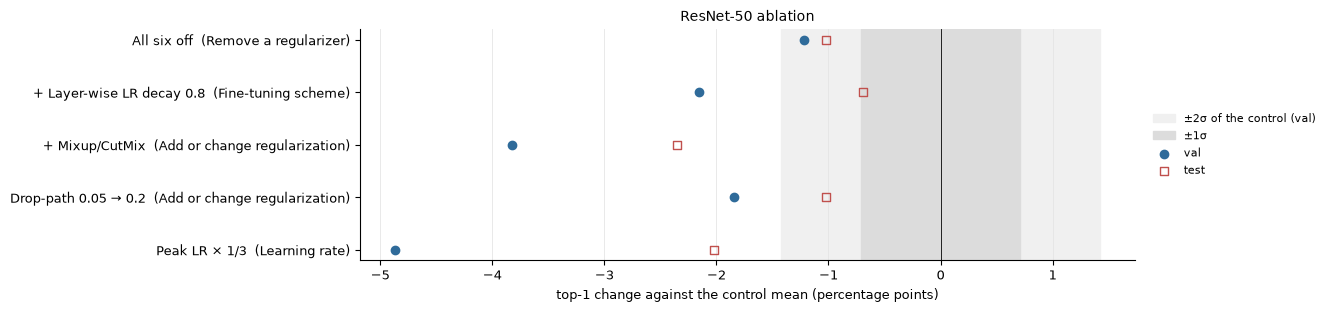

| change | val top-1 | Δ val | Δ val / σ | test top-1 | Δ test | McNemar p (val) | McNemar p (test) | fit − val gap |
|---|---|---|---|---|---|---|---|---|
| All six off | 75.50% | -1.22 pp | -1.7 | 72.84% | -1.02 pp | 0.149 | 0.125 | 24.5 pp |
| + Layer-wise LR decay 0.8 | 74.56% | -2.15 pp | -3.0 | 73.17% | -0.69 pp | 0.024 | 0.156 | 25.4 pp |
| + Mixup/CutMix | 72.89% | -3.82 pp | -5.4 | 71.51% | -2.35 pp | 0.000 | 0.002 | 27.0 pp |
| Drop-path 0.05 → 0.2 | 74.87% | -1.84 pp | -2.6 | 72.84% | -1.02 pp | 0.052 | 0.082 | 24.9 pp |
| Peak LR × 1/3 | 71.85% | -4.87 pp | -6.9 | 71.84% | -2.02 pp | 0.000 | 0.005 | 28.2 pp |

In [14]:
# Draw the ResNet-50 ablation
ablation(RESULTS / "ablation_resnet.csv", "ResNet-50 ablation", 3.0)

For ResNet-50 the seed noise is larger (σ = 0.71 pp), and still every change made it worse. Lowering the learning rate to a third (−6.9σ) and adding Mixup/CutMix (−5.4σ, McNemar p = 0.002 on test) hurt the most. Adding layer-wise decay hurt as well (−3.0σ), the opposite of ConvNeXt-L. Removing all six regularizers hurt too (−1.7σ). The reason is the starting point: ImageNet-1k features have to move far to fit birds, and anything that slows that movement (a lower rate, smaller rates for the early layers, mixed photos and targets, stronger drop-path) costs accuracy. The fit–val gap stays at 24–28 pp in every run, so no recipe change closes it.

### 8.7 Which photos are learned when: per-epoch predictions

The run saved its val and fit-subset logits after every epoch (`runs/<run>/epochs/`). From them: which species become reliable early or late, how often a photo's prediction flips between right and wrong, and whether the EMA weights steady those flips. A flip on a training photo, right then wrong, is a "forgetting event" (Toneva et al., 2019).

ema_val: 20 epochs × 959 photos; recomputed accuracy matches metrics.jsonl in 20 of 20 epochs (otherwise off by one photo)
val: 20 epochs × 959 photos; recomputed accuracy matches metrics.jsonl in 20 of 20 epochs (otherwise off by one photo)
ema_train_eval: 20 epochs × 922 photos; recomputed accuracy matches metrics.jsonl in 20 of 20 epochs (otherwise off by one photo)
train_eval: 20 epochs × 922 photos; recomputed accuracy matches metrics.jsonl in 20 of 20 epochs (otherwise off by one photo)


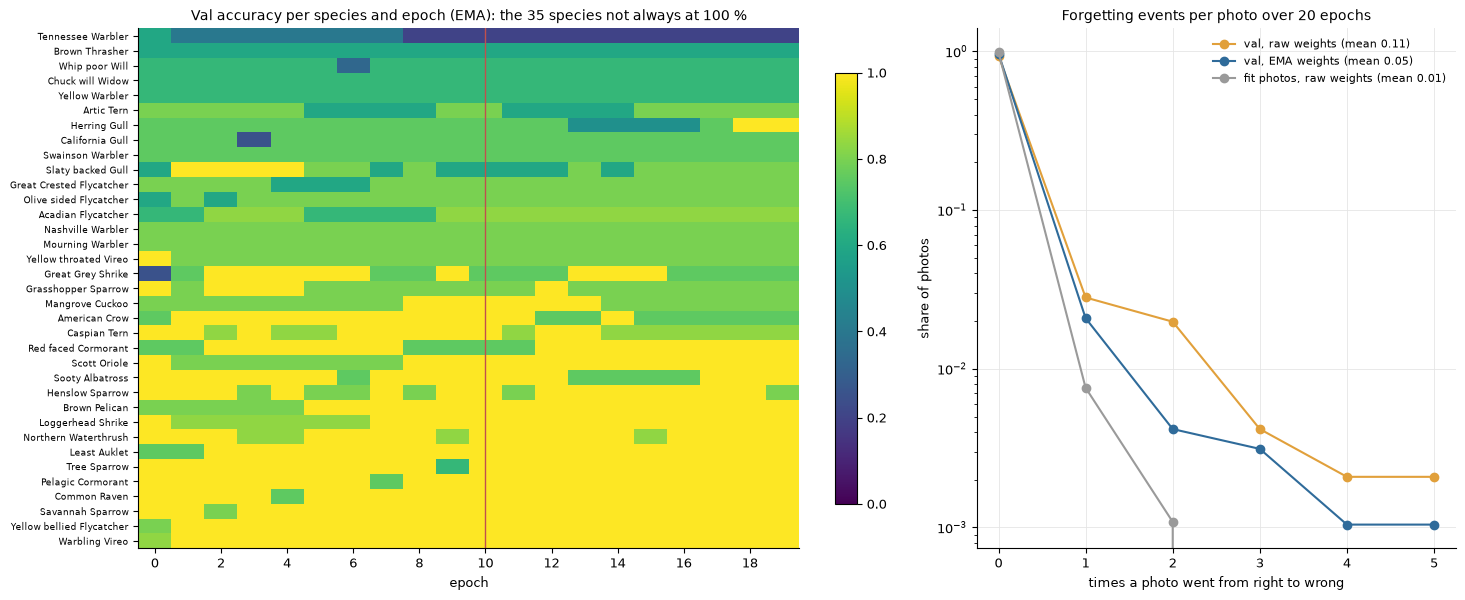

| species | group | val photos | flips (raw weights) | val accuracy at the kept epoch (EMA) |
|---|---|---|---|---|
| Slaty backed Gull | Gull | 5 | 7 | 60% |
| Northern Waterthrush | Waterthrush | 6 | 6 | 100% |
| Mangrove Cuckoo | Cuckoo | 5 | 6 | 100% |
| Great Grey Shrike | Shrike | 4 | 5 | 75% |
| Grasshopper Sparrow | Sparrow | 5 | 5 | 80% |
| Henslow Sparrow | Sparrow | 5 | 5 | 100% |
| American Crow | Crow | 4 | 4 | 100% |
| Olive sided Flycatcher | Flycatcher | 5 | 4 | 80% |
| Common Raven | Raven | 4 | 4 | 100% |
| Acadian Flycatcher | Flycatcher | 6 | 3 | 83% |

15 val photos are never right under the EMA weights; 24 are wrong at the kept epoch 10


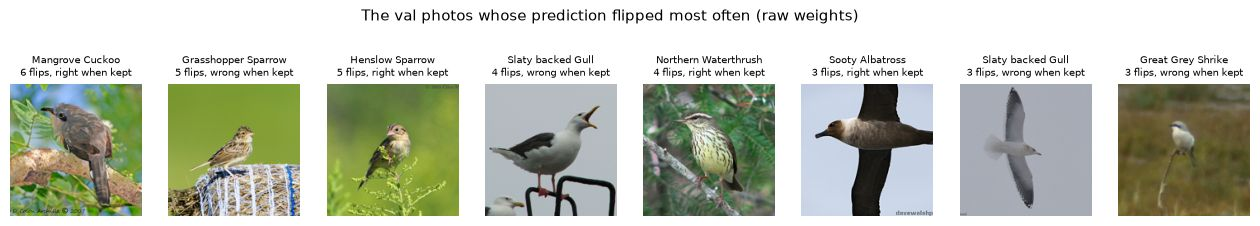

In [15]:
# Load per-epoch logits
EPOCHS = RUNS / FINAL / "epochs"
index = np.load(EPOCHS / "index.npz")
epoch_files = sorted(EPOCHS.glob("epoch_*.npz"))

# Score every epoch
correct = {}
for split in ("val", "train_eval"):
    labels = index[f"{split}_labels"]
    for weights in ("ema_", ""):
        key = f"{weights}{split}"
        correct[key] = np.array([
            tta_probs(z[f"{key}_center"].astype(np.float32), z[f"{key}_hflip"].astype(np.float32)).argmax(1)
            == labels for z in map(np.load, epoch_files)])
# The recomputed accuracies must match what the run logged at the time. The saved logits are fp16
# copies, so a near-tie could at most move a single photo.
for key, hits in correct.items():
    photos_off = np.abs(hits.sum(1) - series(f"{key}_top1") * hits.shape[1]).round().astype(int)
    assert photos_off.max() <= 1, (key, photos_off)
    print(f"{key}: {len(epoch_files)} epochs × {hits.shape[1]} photos; recomputed accuracy matches "
          f"metrics.jsonl in {(photos_off == 0).sum()} of {len(photos_off)} epochs (otherwise off by one photo)")

# Get val accuracy per species and epoch
val_labels = index["val_labels"]
per_class = np.array([[c[val_labels == k].mean() for k in range(C)] for c in correct["ema_val"]]).T  # [class, epoch]
unsteady = np.flatnonzero(per_class.min(axis=1) < 1)
order = unsteady[np.argsort(per_class[unsteady].mean(axis=1))]

# Draw accuracy heatmap
fig, axes = plt.subplots(1, 2, figsize=(17, 0.15 * len(order) + 1.5), gridspec_kw={"width_ratios": [1.5, 1]})
im = axes[0].imshow(per_class[order], aspect="auto", cmap="viridis", vmin=0, vmax=1)
axes[0].set_yticks(range(len(order)), [classes[k] for k in order], fontsize=6.5)
axes[0].set(xlabel="epoch", title=f"Val accuracy per species and epoch (EMA): the {len(order)} species not always at 100 %")
axes[0].axvline(best, color=RED, linewidth=1)
axes[0].set_xticks(range(0, len(epoch_files), 2))
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.03)

# Draw forgetting events per photo
for key, color, label in (("val", ORANGE, "val, raw weights"), ("ema_val", BLUE, "val, EMA weights"),
                           ("train_eval", GRAY, "fit photos, raw weights")):
    flips = (correct[key][:-1] & ~correct[key][1:]).sum(axis=0)  # right at one epoch, wrong at the next
    counts = np.bincount(flips, minlength=6)[:6]
    axes[1].plot(range(6), counts / len(flips), "o-", color=color, label=f"{label} (mean {flips.mean():.2f})")
axes[1].set(xlabel="times a photo went from right to wrong", ylabel="share of photos", yscale="log",
            title="Forgetting events per photo over 20 epochs")
axes[1].legend(fontsize=8)
plt.show()

# Count flips per species
raw_flips = (correct["val"][:-1] & ~correct["val"][1:]).sum(axis=0)
by_class_flips = np.bincount(val_labels, weights=raw_flips, minlength=C)
top = np.argsort(-by_class_flips)[:10]
md_table(["species", "group", "val photos", "flips (raw weights)", "val accuracy at the kept epoch (EMA)"],
         [[classes[k], group_of[k], (val_labels == k).sum(), int(by_class_flips[k]),
           pct(per_class[k, best], 0)] for k in top])

# Print never-right photos
never = np.flatnonzero(~correct["ema_val"].any(axis=0))
print(f"{len(never)} val photos are never right under the EMA weights; "
      f"{(~correct['ema_val'][best]).sum()} are wrong at the kept epoch {best}")

# Draw the photos that flipped most
shown = np.argsort(-raw_flips, kind="stable")[:8]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.9))
for ax, i in zip(axes, shown):
    ax.imshow(square(DATA / "Train" / index["val_files"][i], 160))
    ax.set_title(f"{classes[val_labels[i]]}\n{raw_flips[i]} flips, "
                 f"{'right' if correct['ema_val'][best, i] else 'wrong'} when kept", fontsize=7.5)
    ax.axis("off")
fig.suptitle("The val photos whose prediction flipped most often (raw weights)", fontsize=10.5)
show_jpeg(fig)

165 of the 200 species are at 100 % val in every epoch. Most rows of the heatmap are constant stripes: a species' val accuracy is set by the probe head at epoch 0 and hardly changes. A few rows do change. Tennessee Warbler falls from 3 of 5 to 1 of 5; one of its val photos is an identical copy of a fit photo labeled Red-eyed Vireo (Notebook 1, section 5.1). Slaty-backed Gull flips most often (7 times across its 5 val photos) and ends at 3 of 5.

Flips between right and wrong are rare. The EMA weights halve the flips of the raw weights (0.05 against 0.11 per photo): with a decay of 0.998, the EMA averages the weights over about the last 500 updates, which smooths the small shifts of the decision boundary between epochs. The fit photos almost never flip (0.01), because they are learned from the first epoch. 15 val photos are never right in any epoch, and 24 are wrong at the kept epoch. Most errors are therefore fixed by the features from the start, not by when training stops.

→ **Decision:** the EMA weights are kept. Which epoch is kept matters little, because the errors barely depend on it.

## 9. Test results

### 9.1 The required metrics, with uncertainty

The brief asks for top-1 accuracy and average per-class accuracy. Both are computed here with `birdcls.metrics` from the saved test logits. Intervals are 95 % stratified bootstrap intervals: test photos are resampled within each species, so every replicate keeps all 200 species.

In [16]:
# Score the final model
ci = stratified_bootstrap_ci(y_test, pred_test, C, n_boot=2000)
s_val, s_test = summarise(y_val, p_val, C), summarise(y_test, p_test, C)
flags = flagged_test_images(META)
clean = ~np.isin(test_files, list(flags))

# Show metrics
md_table(["metric", "val (959 photos)", "test (1,204 photos)", "test 95 % interval"], [
    ["**top-1 accuracy**", pct(s_val["top1"]), f"**{pct(s_test['top1'])}**",
     f"{pct(ci['top1'][0])} – {pct(ci['top1'][1])}"],
    ["**average per-class accuracy**", pct(s_val["mean_class_acc"]), f"**{pct(s_test['mean_class_acc'])}**",
     f"{pct(ci['mean_class_acc'][0])} – {pct(ci['mean_class_acc'][1])}"],
    ["top-5 accuracy", pct(s_val["top5"]), pct(s_test["top5"]), ""],
    [f"top-1 on the clean subset ({clean.sum():,} photos)", "", pct(top1_accuracy(y_test[clean], pred_test[clean])), ""],
    ["top-1 on the 63 flagged photos", "", pct(top1_accuracy(y_test[~clean], pred_test[~clean])), ""],
    ["NLL, raw → temperature-scaled", f"{nll(final.raw_probs['val'], y_val):.3f} → {nll(p_val, y_val):.3f}",
     f"{nll(final.raw_probs['test'], y_test):.3f} → {nll(p_test, y_test):.3f}", ""],
    ["ECE, raw → temperature-scaled", "",
     f"{expected_calibration_error(final.raw_probs['test'], y_test):.3f} → {expected_calibration_error(p_test, y_test):.3f}", ""],
])

# Check against summary.json
print(f"{(pred_test != y_test).sum()} test errors; summary.json: top-1 {summary['test']['top1']:.4f}, "
      f"mean per-class {summary['test']['mean_class_acc']:.4f}")

| metric | val (959 photos) | test (1,204 photos) | test 95 % interval |
|---|---|---|---|
| **top-1 accuracy** | 97.5% | **96.6%** | 95.7% – 97.4% |
| **average per-class accuracy** | 97.3% | **96.6%** | 95.6% – 97.4% |
| top-5 accuracy | 99.8% | 99.4% |  |
| top-1 on the clean subset (1,141 photos) |  | 96.7% |  |
| top-1 on the 63 flagged photos |  | 95.2% |  |
| NLL, raw → temperature-scaled | 0.174 → 0.120 | 0.234 → 0.192 |  |
| ECE, raw → temperature-scaled |  | 0.063 → 0.015 |  |

41 test errors; summary.json: top-1 0.9659, mean per-class 0.9656


**Test top-1 accuracy is 96.6 % (1,163 of 1,204 photos) and the average per-class accuracy is 96.6 %.** The two agree because each species has 4–8 test photos. Top-5 accuracy is 99.4 %: only 7 test photos do not have the right species among the five most likely. Val (97.5 %) is 0.9 pp higher than test. Both splits carry about ±0.5 pp of sampling noise, and val is also slightly optimiztic, because the kept epoch is the best of 20 on val. The 63 flagged test photos score 95.2 %, below the clean subset's 96.7 %: the 3 errors among them are three of the four exact-conflict photos (section 9.7). Temperature scaling leaves every prediction unchanged and lowers the test NLL from 0.234 to 0.192 and the ECE from 0.063 to 0.015.

### 9.2 What the bootstrap intervals are made of

`stratified_bootstrap_ci` returns only the interval. The cell redraws the same 2,000 replicates with the same seed, so the histograms below are exactly the distributions behind the intervals above.

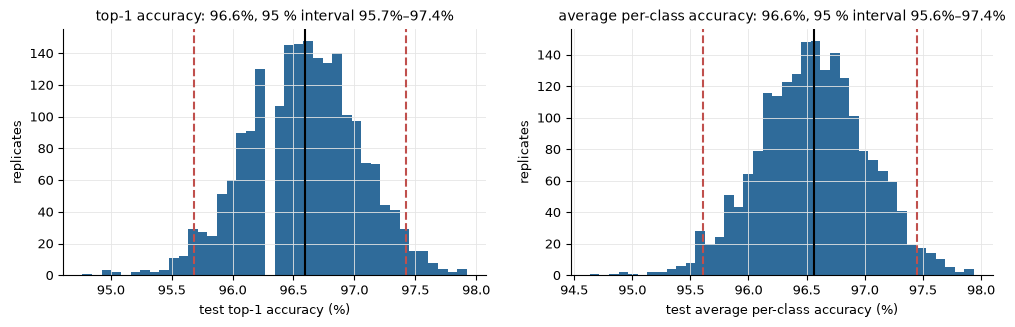

bootstrap standard error: top-1 0.46 pp, per-class 0.46 pp


In [17]:
# Redraw the bootstrap replicates
rng = np.random.default_rng(0)
members = [np.flatnonzero(y_test == c) for c in range(C)]
boot = np.empty((2000, 2))
for b in range(2000):
    idx = np.concatenate([rng.choice(m, size=len(m), replace=True) for m in members])
    boot[b] = top1_accuracy(y_test[idx], pred_test[idx]), np.nanmean(per_class_accuracy(y_test[idx], pred_test[idx], C))
assert np.allclose(np.percentile(boot[:, 0], (2.5, 97.5)), ci["top1"])

# Draw replicates with the interval
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, values, name, key in ((axes[0], boot[:, 0], "top-1 accuracy", "top1"),
                              (axes[1], boot[:, 1], "average per-class accuracy", "mean_class_acc")):
    ax.hist(100 * values, bins=40, color=BLUE)
    for v in ci[key]:
        ax.axvline(100 * v, color=RED, linestyle="--")
    ax.axvline(100 * s_test[key], color="black")
    ax.set(xlabel=f"test {name} (%)", ylabel="replicates",
           title=f"{name}: {pct(s_test[key])}, 95 % interval {pct(ci[key][0])}–{pct(ci[key][1])}")
plt.show()

# Print standard errors
print(f"bootstrap standard error: top-1 {100 * boot[:, 0].std():.2f} pp, per-class {100 * boot[:, 1].std():.2f} pp")

Both distributions have a standard error of 0.46 pp, so the 95 % intervals are about ±0.9 pp wide. Another model scoring within about 1 pp of 96.6 % on this test set cannot be called better or worse from its accuracy alone. A paired test on the same photos (McNemar, section 9.4) is more sensitive, because it ignores the photos that both models get right.

### 9.3 Test-time flip

Every prediction averages the softmax of the photo and of its mirror image. How much does that add?

In [18]:
# Load logits of both views
logits = np.load(RUNS / FINAL / "predictions.npz")
table, correct_view = [], {}

# Compare photo, mirror and average
for split, labels in (("val", y_val), ("test", y_test)):
    center = logits[f"{split}_center"].argmax(1) == labels
    mirror = logits[f"{split}_hflip"].argmax(1) == labels
    both = tta_probs(logits[f"{split}_center"], logits[f"{split}_hflip"]).argmax(1) == labels
    correct_view[split] = (center, both)
    table.append([split, pct(center.mean(), 2), pct(mirror.mean(), 2), pct(both.mean(), 2),
                  f"{mcnemar_exact(both, center)['only_a']} / {mcnemar_exact(both, center)['only_b']}",
                  f"{mcnemar_exact(both, center)['p_value']:.2f}"])

# Show table
md_table(["split", "photo only", "mirror only", "average of both", "photos only the average / only the photo gets right",
          "McNemar p"], table)

| split | photo only | mirror only | average of both | photos only the average / only the photo gets right | McNemar p |
|---|---|---|---|---|---|
| val | 97.39% | 97.39% | 97.50% | 1 / 0 | 1.00 |
| test | 96.18% | 96.59% | 96.59% | 5 / 0 | 0.06 |

Averaging the photo with its mirror image gained 5 test photos and lost none (McNemar p = 0.06), and gained 1 on val. On test, the mirror image alone scores as well as the average, and the unmirrored photo is 0.4 pp lower: an accident of these 1,204 photos, since the network has no preferred direction (it trained on flipped photos half the time).

→ **Decision:** kept. It never hurt, and it costs one extra forward pass per photo.

### 9.4 The ensemble: is it really better?

The report's ensemble of four members was chosen greedily on val log-loss (`scripts/compare_models.py`). McNemar's exact test looks only at the photos where two models disagree on correctness. The cell rebuilds the ensemble from its members' saved predictions and tests it against the best-val single model (the BioCLIP 2.5 probe) and against the final ConvNeXt-L.

In [19]:
# Load ensemble members
ensemble = json.loads((RESULTS / "report" / "ensemble.json").read_text())


# Find a member's prediction file
def source_path(name: str) -> Path:
    kind, stem = name.split(":", 1)
    return FEATURES / "preds" / f"{stem}.npz" if kind == "LP" else RUNS / stem / "predictions.npz"


# Get ensemble and reference predictions
members = [load_source(n, source_path(n), calibrate=True) for n in ensemble["selected_on_val"]]
p_ens = ensemble_probs(members, "test")
reference = load_source(ensemble["reference_single_model"], source_path(ensemble["reference_single_model"]),
                        calibrate=True)
assert np.array_equal(members[0].files["test"], test_files) and np.array_equal(reference.files["test"], test_files)

# Compare with the reference and the final model
right_ens = p_ens.argmax(1) == y_test
print("ensemble members:", ", ".join(m.name for m in members))
for name, right in ((f"best-val single model ({reference.name})", reference.probs["test"].argmax(1) == y_test),
                    ("final ConvNeXt-L", pred_test == y_test)):
    test = mcnemar_exact(right_ens, right)
    md_table([f"ensemble ({pct(right_ens.mean())}) vs {name} ({pct(right.mean())})", "other right", "other wrong"], [
        ["ensemble right", (right_ens & right).sum(), test["only_a"]],
        ["ensemble wrong", test["only_b"], (~right_ens & ~right).sum()]])
    print(f"McNemar exact p = {test['p_value']:.3f} ({test['only_a']} photos only the ensemble gets right, "
          f"{test['only_b']} only the {name.split(' (')[0]})")

ensemble members: LP:eva02_l_inat21__pooled_patch, FT:vit_l_dinov3_336, LP:bioclip25_h__pooled, LP:eva02_l_inat21@448__pooled_patch


| ensemble (97.1%) vs best-val single model (LP:bioclip25_h__pooled) (96.4%) | other right | other wrong |
|---|---|---|
| ensemble right | 1157 | 12 |
| ensemble wrong | 4 | 31 |

McNemar exact p = 0.077 (12 photos only the ensemble gets right, 4 only the best-val single model)


| ensemble (97.1%) vs final ConvNeXt-L (96.6%) | other right | other wrong |
|---|---|---|
| ensemble right | 1155 | 14 |
| ensemble wrong | 8 | 27 |

McNemar exact p = 0.286 (14 photos only the ensemble gets right, 8 only the final ConvNeXt-L)


Against the best single model on val (the BioCLIP 2.5 probe), the ensemble gets 12 photos right that the probe misses and misses 4 that the probe gets right: p = 0.077, the report's figure, not significant at 0.05. Against the final ConvNeXt-L the split is 14 to 8, p = 0.29. With 22 photos on which the two disagree, a 14–8 split is what chance produces about once in three or four repetitions.

→ **Decision:** the web app runs the single ConvNeXt-L. The ensemble does not even contain it: its four members are probes on frozen EVA-02-L features at two input sizes, the fine-tuned DINOv3 ViT-L and a probe on BioCLIP 2.5 ViT-H. That is three backbones with 1.25 B parameters together, six times the final model's 0.2 B, plus the `open_clip` library for BioCLIP, for a gain the test set cannot confirm.

### 9.5 Accuracy per species and per group

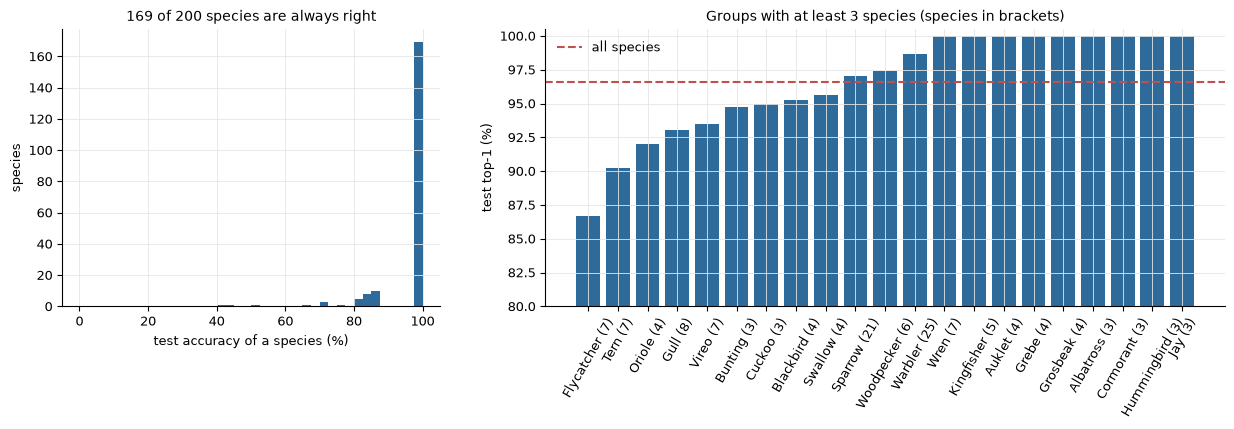

| species | group | test photos | test accuracy | val accuracy | most often predicted instead |
|---|---|---|---|---|---|
| American Crow | Crow | 5 | 40% | 100% | Fish Crow |
| Common Tern | Tern | 7 | 43% | 100% | Artic Tern, Forsters Tern |
| Whip poor Will | Will | 4 | 50% | 67% | Chuck will Widow |
| Fish Crow | Crow | 6 | 67% | 100% | Common Raven, American Crow |
| Acadian Flycatcher | Flycatcher | 7 | 71% | 83% | Sayornis, Least Flycatcher |
| Yellow bellied Flycatcher | Flycatcher | 7 | 71% | 100% | Myrtle Warbler, Great Crested Flycatcher |
| Western Wood Pewee | Pewee | 7 | 71% | 100% | Least Flycatcher |
| Red cockaded Woodpecker | Woodpecker | 4 | 75% | 100% | Downy Woodpecker |
| Brewer Blackbird | Blackbird | 5 | 80% | 100% | Rusty Blackbird |
| American Goldfinch | Goldfinch | 5 | 80% | 100% | Indigo Bunting |
| California Gull | Gull | 5 | 80% | 75% | Ring billed Gull |
| Bank Swallow | Swallow | 5 | 80% | 100% | Barn Swallow |
| Black capped Vireo | Vireo | 5 | 80% | 100% | Blue headed Vireo |
| Painted Bunting | Bunting | 6 | 83% | 100% | Scott Oriole |
| Purple Finch | Finch | 6 | 83% | 100% | American Goldfinch |

In [20]:
# Get per-species accuracy
acc = per_class_accuracy(y_test, pred_test, C)
val_acc = per_class_accuracy(y_val, pred_val, C)
n_test = np.bincount(y_test, minlength=C)

# Draw per-species accuracy
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1.8]})
axes[0].hist(100 * acc, bins=np.arange(0, 102.5, 2.5), color=BLUE)
axes[0].set(xlabel="test accuracy of a species (%)", ylabel="species",
            title=f"{(acc == 1).sum()} of {C} species are always right")

# Draw accuracy per group
groups = [g for g, n in Counter(group_of).most_common() if n >= 3]
group_acc = [(g, correct_test[np.isin(y_test, np.flatnonzero(group_of == g))].mean(),
              np.isin(y_test, np.flatnonzero(group_of == g)).sum(), (group_of == g).sum()) for g in groups]
group_acc.sort(key=lambda t: t[1])
axes[1].bar([f"{g} ({k})" for g, _, _, k in group_acc], [100 * a for _, a, _, _ in group_acc], color=BLUE)
axes[1].axhline(100 * s_test["top1"], color=RED, linestyle="--", label="all species")
axes[1].set(ylim=(80, 100.5), ylabel="test top-1 (%)", title="Groups with at least 3 species (species in brackets)")
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend()
plt.show()

# Show the weakest species
weakest = np.argsort(acc, kind="stable")[:15]
md_table(["species", "group", "test photos", "test accuracy", "val accuracy", "most often predicted instead"], [
    [classes[k], group_of[k], n_test[k], pct(acc[k], 0), pct(val_acc[k], 0),
     ", ".join(classes[j] for j, _ in Counter(pred_test[(y_test == k) & ~correct_test]).most_common(2))]
    for k in weakest])

169 of the 200 species are always right; the 41 errors fall on the other 31. The weakest are the look-alike groups of Notebook 1, section 4.1: American Crow (2 of 5), Common Tern (3 of 7), Whip-poor-will (2 of 4), Fish Crow (4 of 6), and Acadian Flycatcher, Yellow-bellied Flycatcher and Western Wood-Pewee (5 of 7 each). Several of these score 100 % on val, which shows how noisy a single species' accuracy is: with 4–8 photos, one photo moves it by 12–25 pp. Among groups, the flycatchers (86.7 %), terns (90 %), orioles (92 %) and gulls (93 %) are weakest.

### 9.6 Which species are confused with which

41 errors; 66% of them confuse two species of the same group (chance for a random wrong species: 4%)


| species A | species B | errors between them | A taken for B | B taken for A |
|---|---|---|---|---|
| American Crow | Fish Crow | 4 | 3 | 1 |
| Acadian Flycatcher | Least Flycatcher | 2 | 1 | 1 |
| Least Flycatcher | Western Wood Pewee | 2 | 0 | 2 |
| Chuck will Widow | Whip poor Will | 2 | 0 | 2 |
| Artic Tern | Common Tern | 2 | 0 | 2 |
| Brewer Blackbird | Rusty Blackbird | 1 | 1 | 0 |
| Painted Bunting | Scott Oriole | 1 | 1 | 0 |
| Fish Crow | Common Raven | 1 | 1 | 0 |
| Black billed Cuckoo | Yellow billed Cuckoo | 1 | 1 | 0 |
| Purple Finch | American Goldfinch | 1 | 1 | 0 |

| errors | count | same bird | several birds | bird not seen |
|---|---|---|---|---|
| inside a group | 27 | 23 | 2 | 2 |
| across groups | 14 | 10 | 3 | 1 |

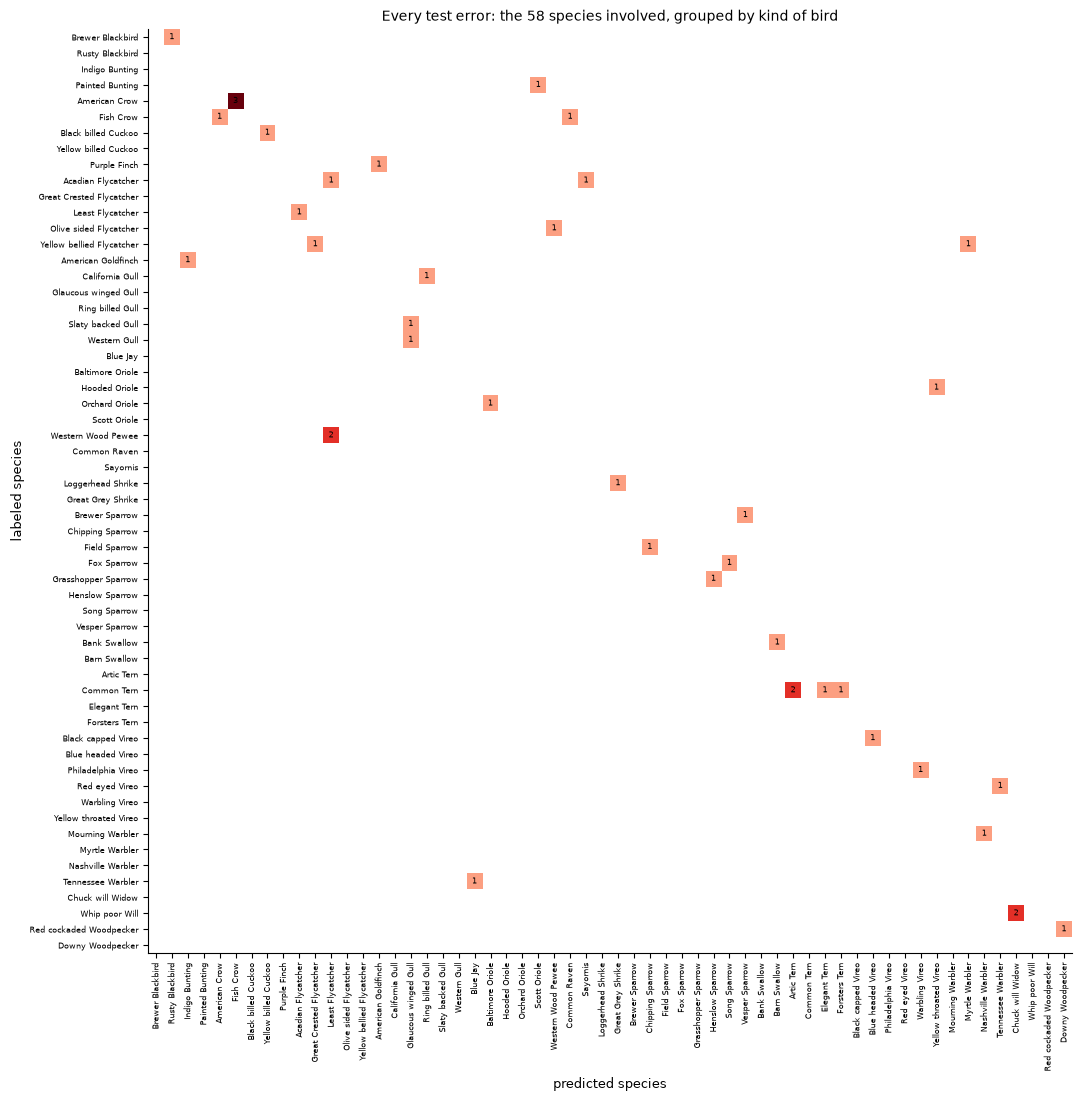

In [21]:
# Count confused pairs
errors = np.flatnonzero(~correct_test)
pairs = Counter(tuple(sorted((y_test[i], pred_test[i]))) for i in errors)
same_group = np.mean(group_of[y_test[errors]] == group_of[pred_test[errors]])
print(f"{len(errors)} errors; {same_group:.0%} of them confuse two species of the same group "
      f"(chance for a random wrong species: {np.mean([(group_of == g).sum() - 1 for g in group_of]) / (C - 1):.0%})")

# Show the top pairs
md_table(["species A", "species B", "errors between them", "A taken for B", "B taken for A"], [
    [classes[a], classes[b], n, sum((y_test[i], pred_test[i]) == (a, b) for i in errors),
     sum((y_test[i], pred_test[i]) == (b, a) for i in errors)] for (a, b), n in pairs.most_common(10)])
# How each error was classified on inspection (section 11.1), inside and across groups.
review = {r["file"]: r for r in read_csv(RESULTS / "gradcam_review.csv")}
FINDINGS = {"same_bird": "same bird", "several_birds": "several birds", "not_seen": "bird not seen"}
within = group_of[y_test[errors]] == group_of[pred_test[errors]]
md_table(["errors", "count"] + list(FINDINGS.values()), [
    [name, m.sum()] + [sum(review[str(test_files[i])]["finding"] == f for i in errors[m]) for f in FINDINGS]
    for name, m in (("inside a group", within), ("across groups", ~within))])

# Build the confusion matrix of the errors
involved = np.unique(np.concatenate([y_test[errors], pred_test[errors]]))
order = involved[np.lexsort((involved, group_of[involved]))]
pos = {c: k for k, c in enumerate(order)}
matrix = np.zeros((len(order), len(order)))
for i in errors:
    matrix[pos[y_test[i]], pos[pred_test[i]]] += 1

# Draw the matrix
fig, ax = plt.subplots(figsize=(13, 12))
ax.imshow(np.ma.masked_equal(matrix, 0), cmap="Reds", vmin=0, vmax=matrix.max())
ax.set_xticks(range(len(order)), [classes[c] for c in order], rotation=90, fontsize=6)
ax.set_yticks(range(len(order)), [classes[c] for c in order], fontsize=6)

# Write counts in cells
for (r, c), v in np.ndenumerate(matrix):
    if v:
        ax.text(c, r, int(v), ha="center", va="center", fontsize=6)

# Set labels and show
ax.set(xlabel="predicted species", ylabel="labeled species",
       title=f"Every test error: the {len(order)} species involved, grouped by kind of bird")
ax.grid(False)
plt.show()

27 of the 41 errors (66 %) confuse two species with the same last name word, against 4 % if the wrong species were picked at random. The naming rule understates the look-alikes. Several "across groups" pairs are close relatives that it splits: Western Wood-Pewee and Least Flycatcher, Chuck-will's-widow and Whip-poor-will (both nightjars), Fish Crow and Common Raven. The most frequent pair, American and Fish Crow (4 errors), is the pair that field guides separate mainly by voice. Of the 14 errors across groups, 4 are photos with several birds or a hard-to-see bird. The table above counts how the review classified each error.

### 9.7 Where the model fails: image size, bird size, duplicates

Three slices of the test set. The short side is the photo's resolution before the model upsamples it to 448 px. Bird size uses a proxy: the box around the region where the Grad-CAM map of the predicted class exceeds 20 % of its peak (maps from `scripts/gradcam_errors.py`), as a share of the 448 × 448 view; it approximates the extent of the evidence, which is usually the bird. Intervals are Wilson 95 % intervals.

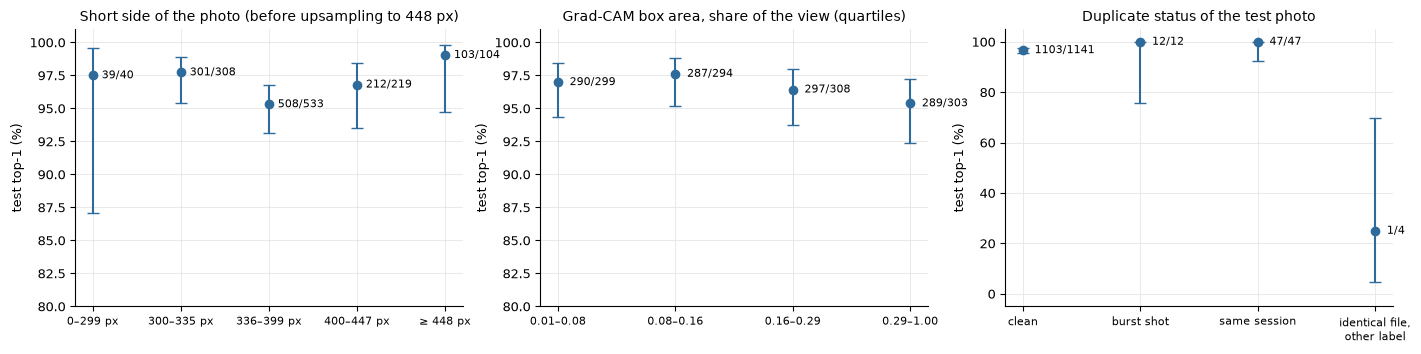

Grad-CAM box area: correct photos median 0.161, errors median 0.188


In [22]:
# Get a Wilson interval
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    p = k / n
    center = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return center - half, center + half


# Get the short side of a photo
def short_side(path: Path) -> int:
    with Image.open(path) as im:
        return min(im.size)


def plot_slices(ax: plt.Axes, slices: list[tuple[str, np.ndarray]]) -> None:
    """Accuracy with a Wilson interval for each slice of the test photos."""
    for k, (_, m) in enumerate(slices):
        lo, hi = wilson(correct_test[m].sum(), m.sum())
        a = correct_test[m].mean()
        ax.errorbar(k, 100 * a, yerr=[[100 * (a - lo)], [100 * (hi - a)]], fmt="o", color=BLUE, capsize=4)
        ax.text(k + 0.1, 100 * a, f"{correct_test[m].sum()}/{m.sum()}", fontsize=8, va="center")
    ax.set_xticks(range(len(slices)), [name for name, _ in slices], fontsize=8)
    ax.set_ylabel("test top-1 (%)")


# Measure photo size and Grad-CAM box area
short = np.array([short_side(DATA / "Test" / f) for f in test_files])
cams = np.load(RUNS / "convnext_l_inat21_448" / "gradcam.npz")
assert np.array_equal(cams["files"], test_files) and np.array_equal(cams["predicted"], pred_test)
boxes = [cam_box(torch.from_numpy(m.astype(np.float32)), 0.2, 0.0) for m in cams["cam_predicted"]]
box_area = np.array([(x1 - x0) * (y1 - y0) for x0, y0, x1, y1 in boxes])

# Photo sizes cluster on a few values (333, 375, 500 px), so the bins are fixed, not quantiles.
size_edges = [0, 300, 336, 400, 448, 10_000]
size_bin = np.digitize(short, size_edges[1:-1])
area_edges = np.quantile(box_area, [0, 0.25, 0.5, 0.75, 1])
area_bin = np.digitize(box_area, area_edges[1:-1])

# Draw accuracy by photo size
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
plot_slices(axes[0], [(f"{lo}–{hi - 1} px" if hi < 10_000 else f"≥ {lo} px", size_bin == b)
                      for b, (lo, hi) in enumerate(pairwise(size_edges)) if (size_bin == b).any()])
axes[0].set(title="Short side of the photo (before upsampling to 448 px)", ylim=(80, 101))

# Draw accuracy by box area
plot_slices(axes[1], [(f"{lo:.2f}–{hi:.2f}", area_bin == b)
                      for b, (lo, hi) in enumerate(pairwise(area_edges))])
axes[1].set(title="Grad-CAM box area, share of the view (quartiles)", ylim=(80, 101))

# Draw accuracy by duplicate status
slices = [("clean", clean)] + [(name, np.isin(test_files, [f for f, r in flags.items() if r == reason]))
                               for name, reason in (("burst shot", "near-same-label"), ("same session", "same-session"),
                                                    ("identical file,\nother label", "exact-conflict"))]
plot_slices(axes[2], slices)
axes[2].set(title="Duplicate status of the test photo", ylim=(-5, 105))
plt.show()

# Print median box areas
print(f"Grad-CAM box area: correct photos median {np.median(box_area[correct_test]):.3f}, "
      f"errors median {np.median(box_area[~correct_test]):.3f}")

None of the three slices shows a trend that would explain the errors:
- **Resolution.** Accuracy does not rise with the photo's resolution: the 336–399 px bin, the largest, is the lowest at 95.3 %, and all intervals overlap.
- **Bird size.** The proxy points the other way from "small birds are hard": the largest quartile of Grad-CAM boxes has the lowest accuracy (95.4 %), and errors have larger boxes than correct photos (median 0.188 against 0.161 of the view). A spread-out map more often signals uncertain or split evidence than a large bird.
- **Duplicates.** Every burst shot (12 of 12) and same-session photo (47 of 47) is right. Only 1 of the 4 exact conflicts is right: 0976, whose identical twin labeled Tennessee Warbler sits in the val split, so the model never trained on the conflicting label. The other three have their twin in the fit split, so a model that fits its training labels must get them wrong.

→ **Decision:** neither a higher input resolution nor a zoom onto the bird is likely to fix the remaining errors. The project's CAM-guided zoom (`scripts/cam_zoom.py`) brought no gain on val and is switched off in the app (`zoom: null` in its calibration).

### 9.8 Can the displayed confidence be trusted?

Fine-tuning with label smoothing leaves the network under-confident. One temperature fitted on val rescales the probabilities without changing any prediction. The web app shows "not sure" below a confidence threshold, chosen on val so that the answers it does give are 99 % right (`scripts/build_app_bundle.py`); the app averages the logits of the photo and its mirror and divides by its own temperature, which the cell reproduces.

val: at the app's threshold 0.85, 95.5% of photos get an answer and 99.0% of those answers are right (9 wrong answers shown, 43 photos answered 'not sure', of which 28 would have been right)
test: at the app's threshold 0.85, 94.4% of photos get an answer and 98.1% of those answers are right (22 wrong answers shown, 68 photos answered 'not sure', of which 49 would have been right)


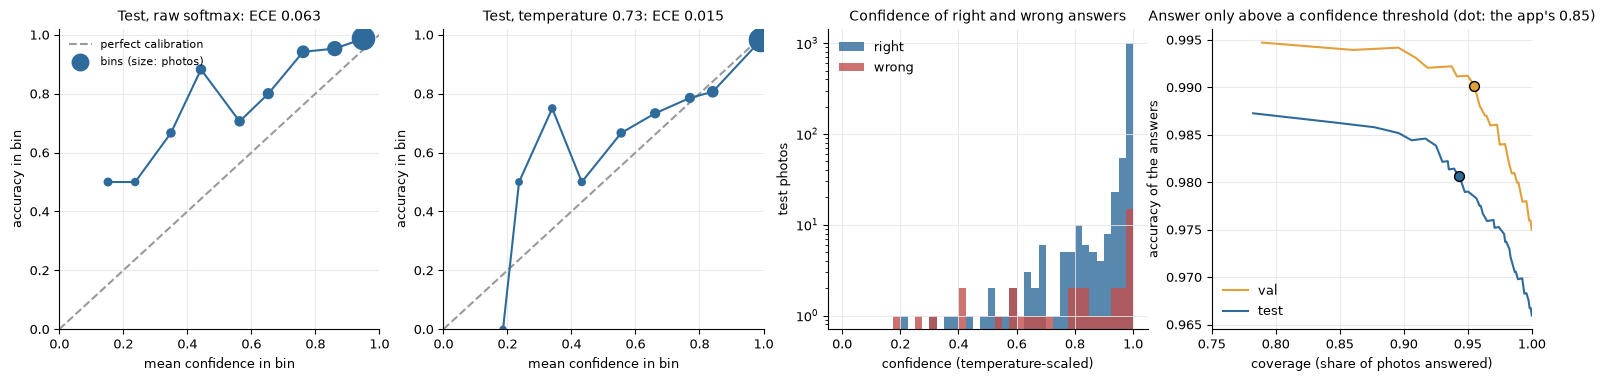

In [23]:
# Load the app calibration
calibration = json.loads((BUNDLE / "calibration.json").read_text())


# Draw a reliability diagram
def reliability(ax: plt.Axes, probs: np.ndarray, labels: np.ndarray, title: str) -> None:
    conf, right = probs.max(1), probs.argmax(1) == labels
    edges = np.linspace(0, 1, 11)
    which = np.clip(np.digitize(conf, edges) - 1, 0, 9)

    # Average confidence and accuracy per bin
    centers, accs, counts = [], [], []
    for b in range(10):
        m = which == b
        if m.any():
            centers.append(conf[m].mean())
            accs.append(right[m].mean())
            counts.append(m.sum())

    # Draw bins against the diagonal
    ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", label="perfect calibration")
    ax.scatter(centers, accs, s=10 + 2 * np.sqrt(counts) * 4, color=BLUE, zorder=3, label="bins (size: photos)")
    ax.plot(centers, accs, color=BLUE)
    ax.set(xlabel="mean confidence in bin", ylabel="accuracy in bin",
           title=f"{title}: ECE {expected_calibration_error(probs, labels):.3f}", xlim=(0, 1), ylim=(0, 1.02))


# Reproduce the app's probabilities and threshold
app_t = calibration["temperature"]
app_probs = {split: softmax((logits[f"{split}_center"] + logits[f"{split}_hflip"]) / 2 / app_t) for split in ("val", "test")}
threshold, coverage, sel_acc = selective_threshold(app_probs["val"], y_val, 0.99)
assert threshold == calibration["abstain_threshold"]

# Draw reliability before and after scaling
fig, axes = plt.subplots(1, 4, figsize=(19, 3.9))
reliability(axes[0], final.raw_probs["test"], y_test, "Test, raw softmax")
reliability(axes[1], p_test, y_test, f"Test, temperature {final.temperature:.2f}")
axes[0].legend(loc="upper left", fontsize=8)

# Draw confidence of right and wrong answers
conf = p_test.max(1)
axes[2].hist(conf[correct_test], bins=np.linspace(0, 1, 41), color=BLUE, alpha=0.8, label="right")
axes[2].hist(conf[~correct_test], bins=np.linspace(0, 1, 41), color=RED, alpha=0.8, label="wrong")
axes[2].set(yscale="log", xlabel="confidence (temperature-scaled)", ylabel="test photos",
            title="Confidence of right and wrong answers")
axes[2].legend()

# Draw accuracy against coverage
thresholds = np.linspace(0, 0.99, 100)
for split, labels, color in (("val", y_val, ORANGE), ("test", y_test, BLUE)):
    c = app_probs[split].max(1)
    right = app_probs[split].argmax(1) == labels
    cov = np.array([(c >= t).mean() for t in thresholds])
    accuracy = np.array([right[c >= t].mean() for t in thresholds])
    axes[3].plot(cov, accuracy, color=color, label=split)

    # Mark the app's threshold
    m = c >= threshold
    axes[3].scatter(m.mean(), right[m].mean(), color=color, s=50, edgecolors="black", zorder=3)
    print(f"{split}: at the app's threshold {threshold:.2f}, {m.mean():.1%} of photos get an answer and "
          f"{right[m].mean():.1%} of those answers are right ({(~right[m]).sum()} wrong answers shown, "
          f"{(~m).sum()} photos answered 'not sure', of which {(right[~m]).sum()} would have been right)")

# Set labels and show
axes[3].set(xlabel="coverage (share of photos answered)", ylabel="accuracy of the answers",
            title=f"Answer only above a confidence threshold (dot: the app's {threshold:.2f})", xlim=(0.75, 1.0))
axes[3].legend()
plt.show()

The raw network is **under-confident**: in every confidence bin, the accuracy lies above the diagonal (ECE 0.063). The cause is label smoothing (section 8.1). A temperature of 0.73, below 1, sharpens the probabilities and brings the ECE to 0.015. After scaling, 92 % of right answers have a confidence above 0.95. The wrong ones spread from 0.19 to 1.0, and 17 of them are above 0.95, including three duplicate conflicts and confident look-alike mistakes. No threshold can filter those out.

The app's threshold of 0.85 was chosen on val as the lowest, in steps of 0.05, that makes the answers it gives 99 % right. On val it answers 95.5 % of photos and 99.0 % of those answers are right. On test it answers 94.4 %, of which 98.1 % are right: 22 wrong answers are shown, and of the 68 photos answered "not sure", 49 would have been right. Test falls 0.9 pp short of the 99 % target, the same val optimizm as in section 9.1.

→ **Decision:** the app shows the temperature-scaled confidence and answers "not sure" below 0.85.

### 9.9 All the models compared

The report's comparison (`results/report/comparison.csv`): every model trained on the fit split, selected on val, scored once on test.

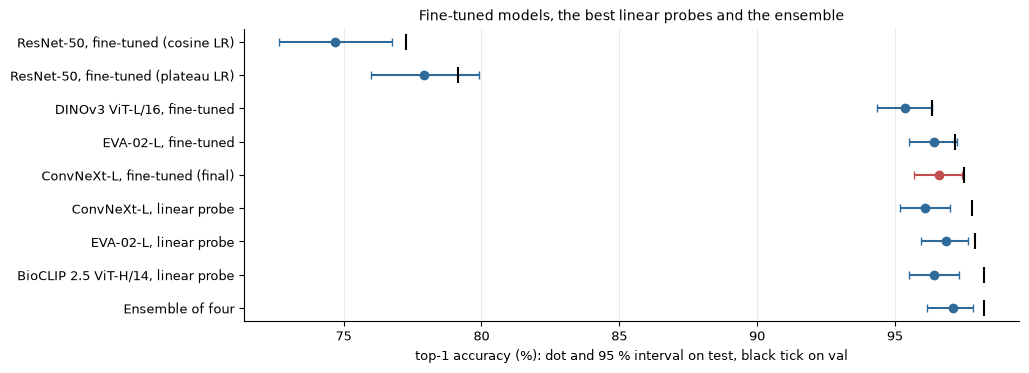

| model | val top-1 | test top-1 | test per-class | test top-5 | clean test | test ECE |
|---|---|---|---|---|---|---|
| ResNet-50, fine-tuned (cosine LR) | 77.3% | 74.7% | 74.1% | 91.5% | 73.7% | 0.029 |
| ResNet-50, fine-tuned (plateau LR) | 79.1% | 77.9% | 77.5% | 93.1% | 77.0% | 0.037 |
| DINOv3 ViT-L/16, fine-tuned | 96.4% | 95.3% | 95.5% | 99.3% | 95.4% | 0.015 |
| EVA-02-L, fine-tuned | 97.2% | 96.4% | 96.4% | 99.7% | 96.6% | 0.016 |
| ConvNeXt-L, fine-tuned (final) | 97.5% | 96.6% | 96.6% | 99.4% | 96.7% | 0.015 |
| ConvNeXt-L, linear probe | 97.8% | 96.1% | 96.1% | 99.4% | 96.2% | 0.019 |
| EVA-02-L, linear probe | 97.9% | 96.8% | 96.9% | 99.8% | 97.0% | 0.020 |
| BioCLIP 2.5 ViT-H/14, linear probe | 98.2% | 96.4% | 96.4% | 99.3% | 96.6% | 0.016 |
| Ensemble of four | 98.2% | 97.1% | 97.1% | 99.6% | 97.3% | 0.014 |

In [24]:
# Load the model comparison
comparison = ra.comparison()
rows = [(comparison[key], label) for key, label, _, _ in ra.MAIN_ROWS]

# Draw test intervals and val ticks
fig, ax = plt.subplots(figsize=(10, 3.8))
yy = np.arange(len(rows))[::-1]
for y_pos, (r, label) in zip(yy, rows):
    t, lo, hi = (float(r[k]) for k in ("test_top1", "test_top1_lo", "test_top1_hi"))
    color = RED if r["name"] == ra.FINAL_ROW else BLUE
    ax.errorbar(100 * t, y_pos, xerr=[[100 * (t - lo)], [100 * (hi - t)]], fmt="o", color=color, capsize=3)
    ax.scatter(100 * float(r["val_top1"]), y_pos, marker="|", s=120, color="black", zorder=3)

# Set labels and show
ax.set_yticks(yy, [label for _, label in rows])
ax.set(xlabel="top-1 accuracy (%): dot and 95 % interval on test, black tick on val",
       title="Fine-tuned models, the best linear probes and the ensemble")
ax.grid(axis="y", visible=False)
plt.show()

# Show table
md_table(["model", "val top-1", "test top-1", "test per-class", "test top-5", "clean test", "test ECE"], [
    [label, pct(float(r["val_top1"])), pct(float(r["test_top1"])), pct(float(r["test_mean_class_acc"])),
     pct(float(r["test_top5"])), pct(float(r["test_top1_clean"])), f"{float(r['test_ece']):.3f}"] for r, label in rows])

The fine-tuned models and the best probes of species-pretrained backbones all lie between 95.3 % and 97.1 % on test, with overlapping intervals; the two ResNet-50 models are about 20 pp lower. Fine-tuning adds 0.5 pp on test to the ConvNeXt-L probe (96.1 % to 96.6 %), but 10.7–13.9 pp to the ResNet-50 probe. The closer the pretraining is to birds, the less fine-tuning has left to add. The probes score higher on val than any fine-tuned model (97.8–98.2 % against at most 97.5 %), but on test they are level with them (96.1–96.8 % against 95.3–96.6 %). The final model is the best fine-tuned model on val; on test it ties EVA-02-L. After temperature scaling, every large model's test ECE is 0.014–0.020.

## 10. Grad-CAM, computed live

Grad-CAM asks where in the photo the network found the evidence for a class. It takes the last convolutional feature map, weights each channel by the average gradient of the class score with respect to it, adds the weighted channels and keeps the positive part (`birdcls.cam.grad_cam`). The cell loads the final weights, checks they are the deployed ones, and computes the maps for six right and six wrong test photos on this machine. For a wrong photo it shows two maps: the evidence for the predicted species and for the labeled one.

best_ema.pt: 1ae882b1c63fe1a9…; web app's model.pt identical: True; embeddings made by these weights: True


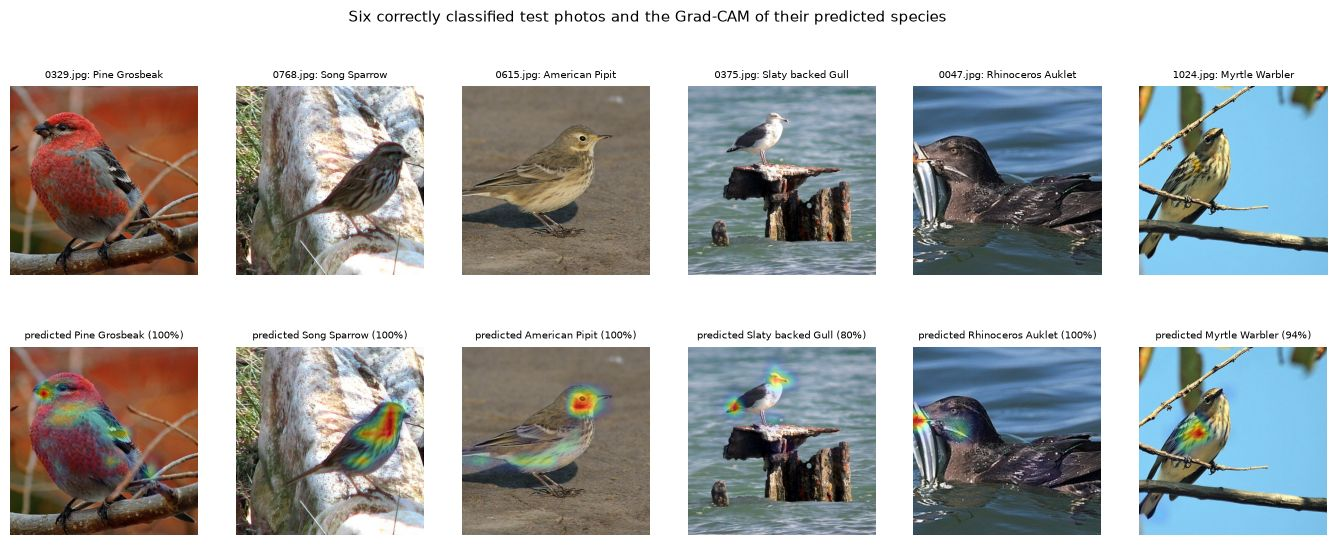

6 maps in 1.2 s on mps; correlation with the stored 32 × 32 maps: 1.000–1.000


In [25]:
# Hash a file
# Check the weights match the app
weights_hash = sha256_file(WEIGHTS)
print(f"best_ema.pt: {weights_hash[:16]}…; web app's model.pt identical: {sha256_file(BUNDLE / 'model.pt') == weights_hash}; "
      f"embeddings made by these weights: {str(app['weights_sha256']) == weights_hash}")

# Load the weights
state = torch.load(WEIGHTS, map_location="cpu", weights_only=True)
model.load_state_dict({k: v.float() for k, v in state.items()})
model.to(device).eval()
eval_tf = build_eval_transform(cfg.img_size, data_cfg["mean"], data_cfg["std"], cfg.eval_crop_pct)


# Draw a heat map over a photo
def overlay(ax: plt.Axes, image: np.ndarray, cam: np.ndarray, title: str) -> None:
    rgba = matplotlib.colormaps["jet"](cam)
    rgba[..., 3] = 0.7 * cam  # weak evidence stays transparent, so the photo shows through
    ax.imshow(image)
    ax.imshow(rgba, extent=(0, image.shape[1], image.shape[0], 0))
    ax.set_title(title, fontsize=7.5)
    ax.axis("off")


def view_of(file: str) -> tuple[torch.Tensor, np.ndarray]:
    """The network input of a test photo, and the same crop as an RGB image for display."""
    with Image.open(DATA / "Test" / file) as im:
        x = eval_tf(im.convert("RGB"))
    view = (x * torch.tensor(data_cfg["std"])[:, None, None] + torch.tensor(data_cfg["mean"])[:, None, None]).clamp(0, 1)
    return x, view.permute(1, 2, 0).numpy()


# Pick six correct test photos
rng = np.random.default_rng(SEED)
right_shown = rng.choice(np.flatnonzero(correct_test), 6, replace=False)

# Compute and draw Grad-CAM
start = time.perf_counter()
fig, axes = plt.subplots(2, 6, figsize=(17, 6.2))
agreement = []
for col, i in enumerate(right_shown):
    # Compute the map
    x, view = view_of(test_files[i])
    cam, out = grad_cam(model, x[None].to(device))
    cam = cam[0].cpu().numpy()

    # Compare with the stored map
    stored = cams["cam_predicted"][i].astype(np.float32)
    pooled = F.adaptive_avg_pool2d(torch.from_numpy(cam)[None, None], 32).numpy()
    agreement.append(np.corrcoef(pooled.ravel(), stored.ravel())[0, 1])

    # Draw the photo and the map
    axes[0, col].imshow(view)
    axes[0, col].set_title(f"{test_files[i]}: {classes[y_test[i]]}", fontsize=7.5)
    axes[0, col].axis("off")
    overlay(axes[1, col], view, cam, f"predicted {classes[int(out.argmax())]} ({pct(p_test[i].max(), 0)})")

# Add title and show
fig.suptitle("Six correctly classified test photos and the Grad-CAM of their predicted species", fontsize=11)
show_jpeg(fig)

# Print timing and agreement
print(f"6 maps in {time.perf_counter() - start:.1f} s on {device}; correlation with the stored 32 × 32 maps: "
      f"{min(agreement):.3f}–{max(agreement):.3f}")

The weights are the deployed ones (SHA-256 match with the app's `model.pt` and with the embeddings of section 7.4), and the maps computed live on this machine match the stored ones exactly (correlation 1.000). The evidence sits on the bird, mostly on parts a birder would use: the Pine Grosbeak's head, the Song Sparrow's streaked breast, the American Pipit's head, the Myrtle Warbler's yellow flank, the Rhinoceros Auklet's bill with its catch. For the Slaty-backed Gull, the least confident of the six (80 %), the evidence splits between the head and the wing tips, where the gulls differ.

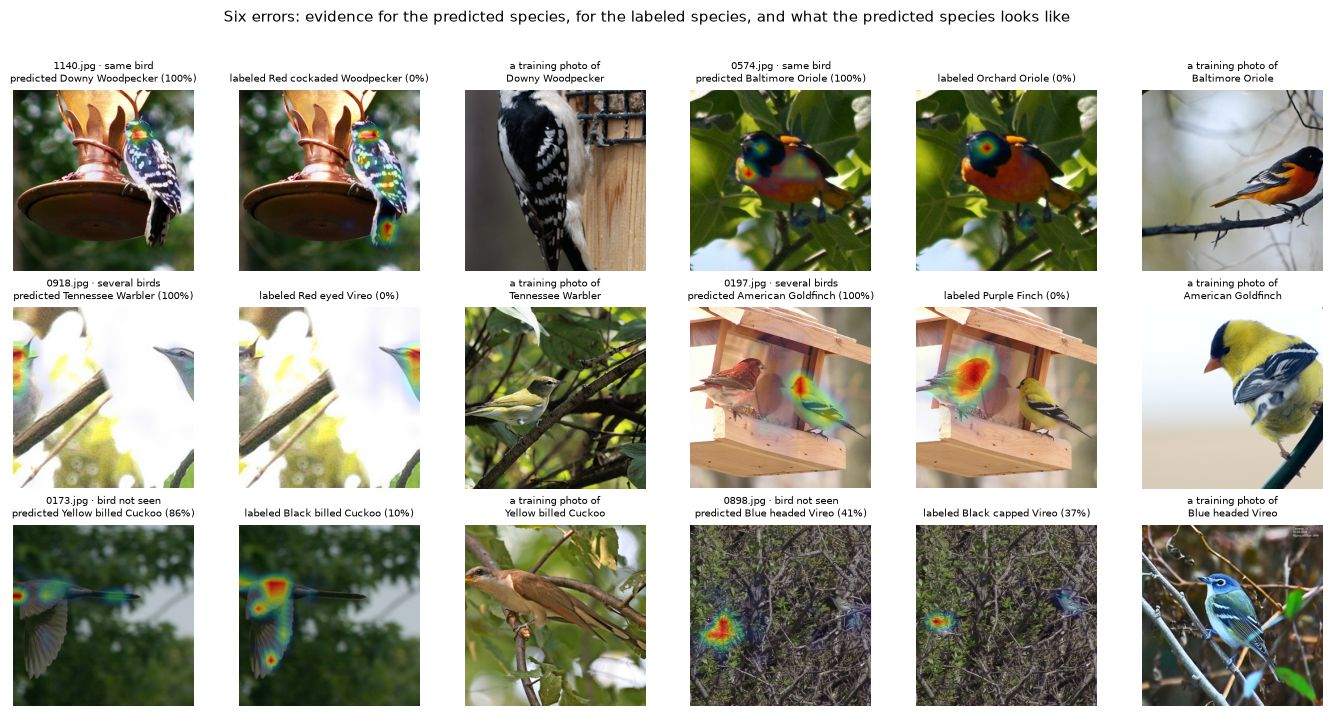

In [26]:
# Pick two errors of each finding
used, wrong_shown = set(), []
for finding in ("same_bird", "same_bird", "several_birds", "several_birds", "not_seen", "not_seen"):
    i = next(i for i in errors[np.argsort(-p_test[errors].max(1))]
             if review[str(test_files[i])]["finding"] == finding and i not in used)
    used.add(i)
    wrong_shown.append(i)

# Draw both maps and a photo of the predicted species
fig, axes = plt.subplots(len(wrong_shown) // 2, 6, figsize=(17, 2.9 * len(wrong_shown) // 2))
for k, i in enumerate(wrong_shown):
    # Compute maps for the predicted and labeled species
    x, view = view_of(test_files[i])
    cam_pred, _ = grad_cam(model, x[None].to(device))
    cam_true, _ = grad_cam(model, x[None].to(device), torch.tensor([int(y_test[i])], device=device))

    # Draw the three panels
    row, col = divmod(k, 2)
    ax = axes[row, 3 * col: 3 * col + 3]
    overlay(ax[0], view, cam_pred[0].cpu().numpy(), f"{test_files[i]} · {FINDINGS[review[str(test_files[i])]['finding']]}\n"
            f"predicted {classes[pred_test[i]]} ({pct(p_test[i, pred_test[i]], 0)})")
    overlay(ax[1], view, cam_true[0].cpu().numpy(), f"\nlabeled {classes[y_test[i]]} ({pct(p_test[i, y_test[i]], 0)})")
    ax[2].imshow(square(train_photo[pred_test[i]], 224))
    ax[2].set_title(f"a training photo of\n{classes[pred_test[i]]}", fontsize=7.5)
    ax[2].axis("off")

# Add title and show
fig.suptitle("Six errors: evidence for the predicted species, for the labeled species, and what the predicted "
             "species looks like", fontsize=11)
show_jpeg(fig)

Three kinds of errors, two photos each:
- **Several birds** (0918, 0197, both exact conflicts from Notebook 1). The map for the predicted species and the map for the labeled species land on **two different birds**. The model sees both species correctly and names the one its identical training copy was labeled with.
- **Same bird** (1140, 0574). Both maps cover the same bird, and the model gives the labeled species 0 %. In 0574 the bird is orange and black like the Baltimore Oriole training photo beside it, while an adult male Orchard Oriole is chestnut and black. This may be a labeling error in `test.txt` rather than a model error, which only an expert could settle.
- **Bird not seen** (0173, 0898). The bird is a blur in flight or a few pixels in dense twigs. 0898 is answered with only 41 % confidence, so the app would reply "not sure". 0173 is answered with 86 %, just above the 0.85 threshold, so the app would show a wrong answer.

## 11. The remaining errors

### 11.1 All test errors

Every error was inspected with its two Grad-CAM maps and sorted into three findings (`results/gradcam_review.csv`): the model looked at the right bird and took it for a look-alike (*same bird*), the photo shows several birds and the model named another one (*several birds*), or the bird is hard to see at all in the model's center crop (*bird not seen*). Below: each error with a training photo of the predicted and of the labeled species, most confident mistakes first.

| finding | errors |
|---|---|
| same bird | 33 |
| several birds | 5 |
| bird not seen | 3 |

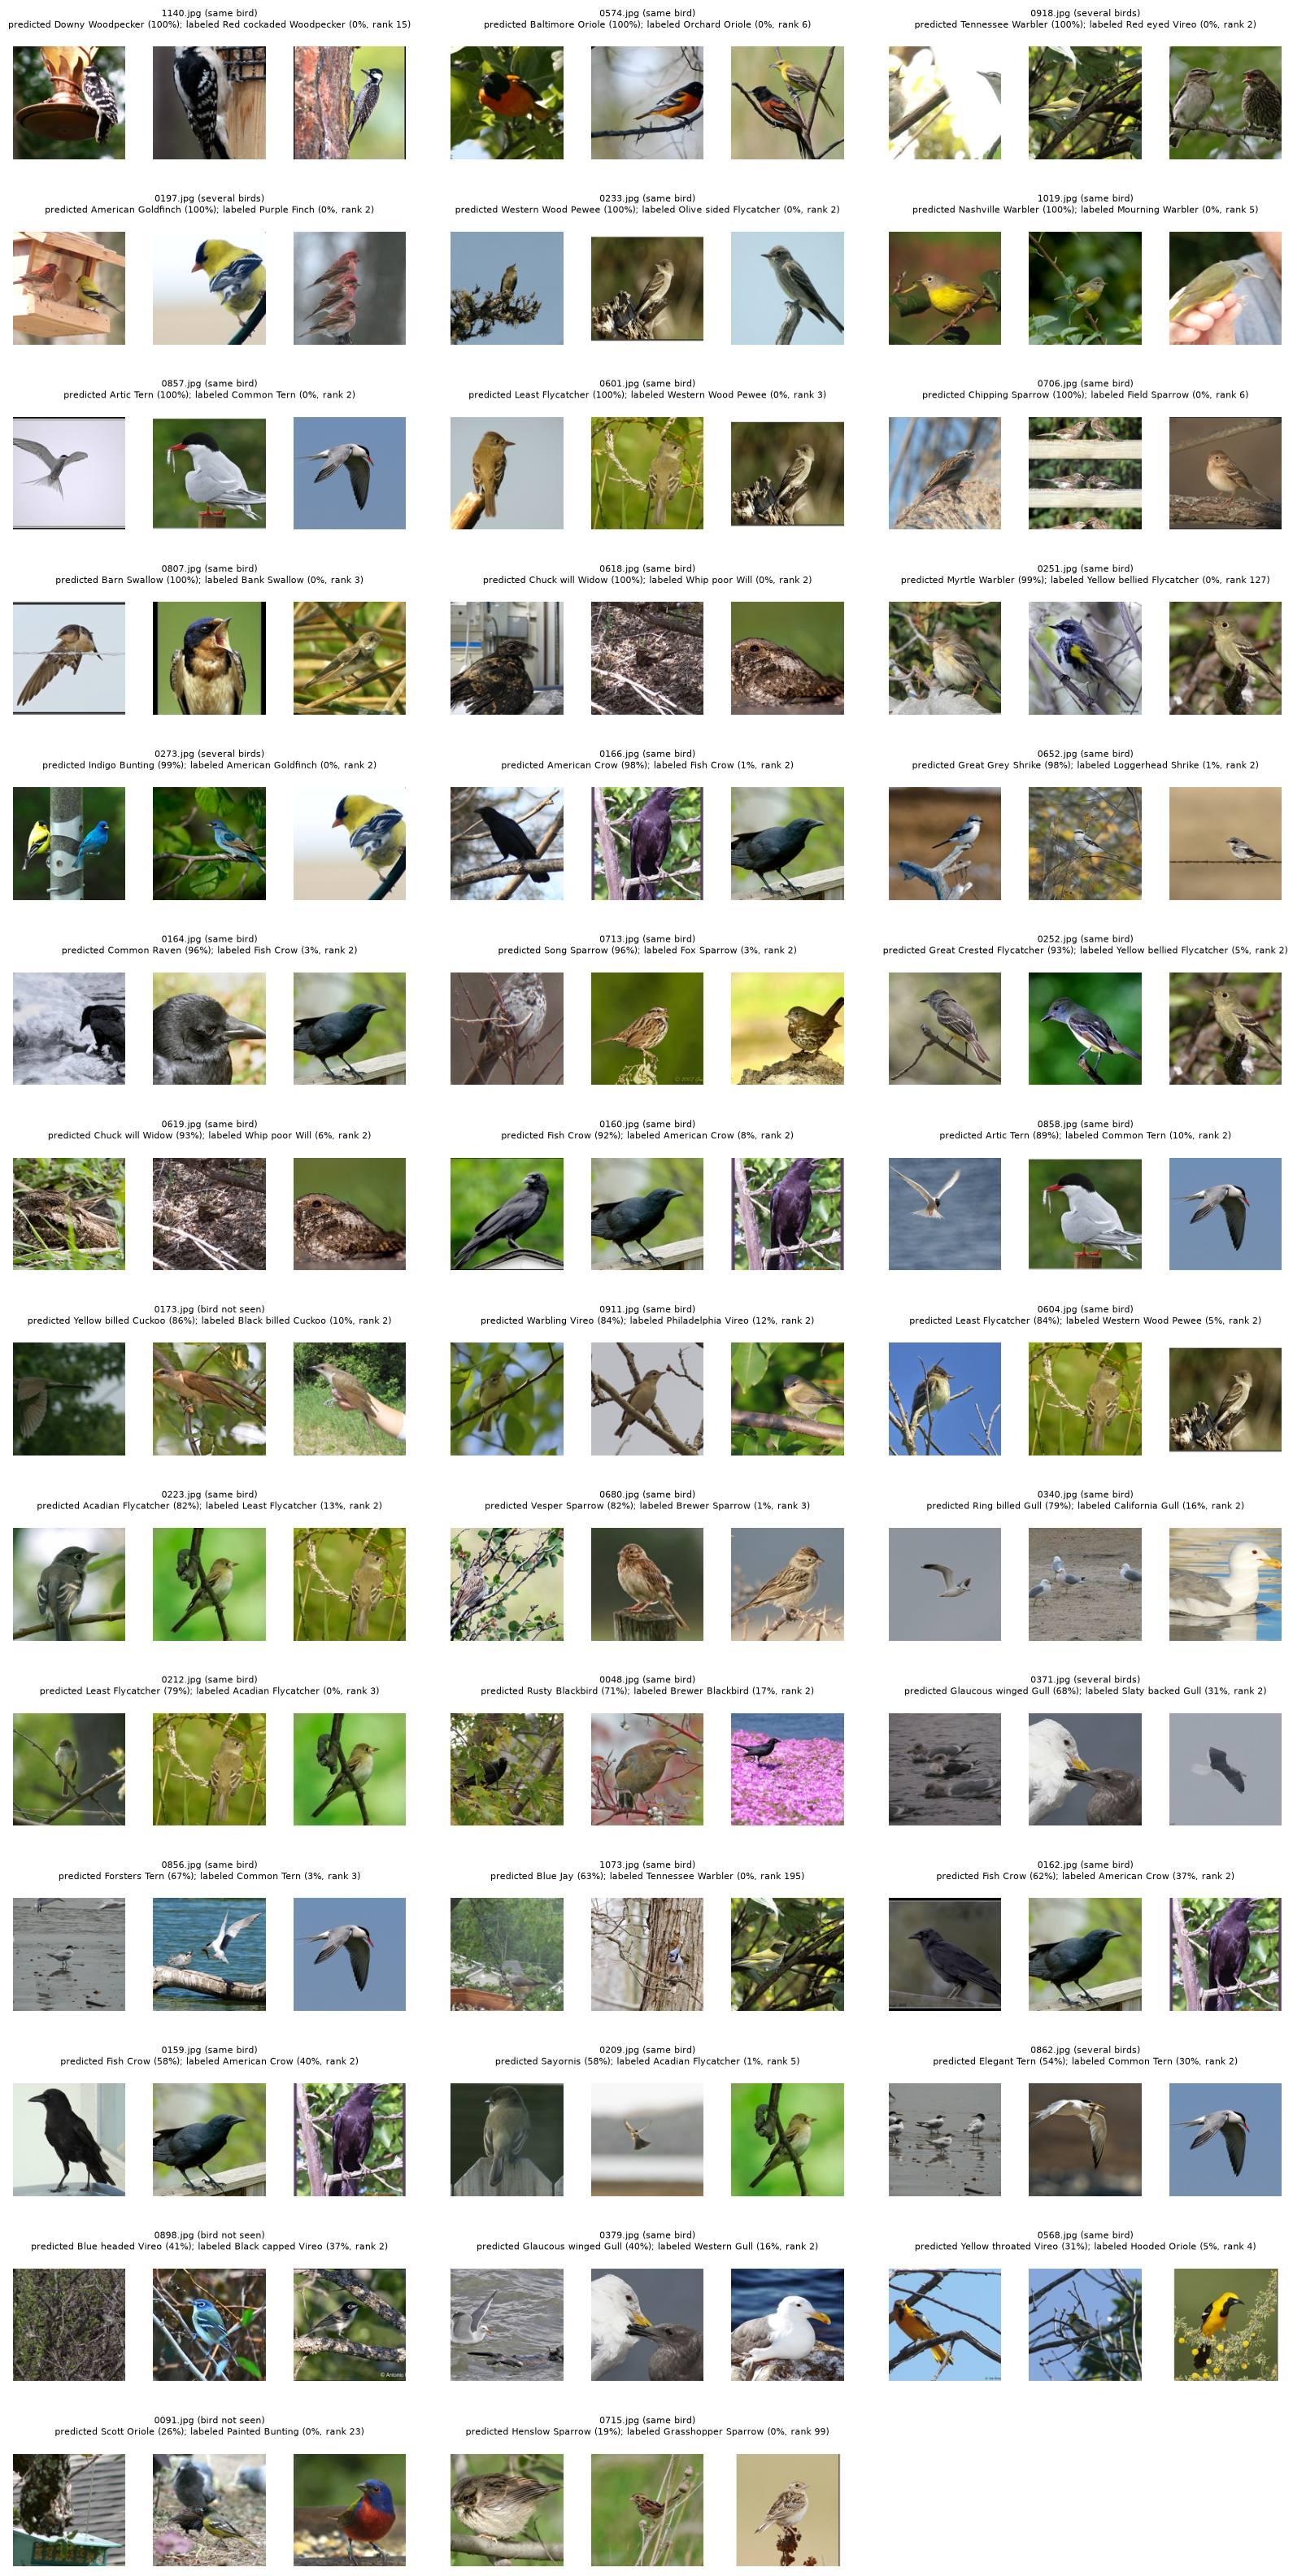

the labeled species is the model's second choice in 26 of 41 errors and outside its top 10 in 5: 0091.jpg (rank 23), 0251.jpg (rank 127), 0715.jpg (rank 99), 1073.jpg (rank 195), 1140.jpg (rank 15)


In [27]:
# Count findings
md_table(["finding", "errors"], [[FINDINGS[f], n] for f, n in
                                 Counter(review[str(test_files[i])]["finding"] for i in errors).most_common()])
assert len(review) == len(errors)

# Draw every error, most confident first
ordered = errors[np.argsort(-p_test[errors].max(1), kind="stable")]
cols = 3
rows_n = (len(ordered) + cols - 1) // cols
fig = plt.figure(figsize=(16, 2.25 * rows_n))
for panel, i in zip(fig.subfigures(rows_n, cols, wspace=0.03).flat, ordered):
    axes = panel.subplots(1, 3, gridspec_kw={"wspace": 0.03, "top": 0.74, "bottom": 0.01, "left": 0.01, "right": 0.99})

    # Draw the test photo and two training photos
    for ax, image in zip(axes, (square(DATA / "Test" / test_files[i], 150), square(train_photo[pred_test[i]], 150),
                                square(train_photo[y_test[i]], 150))):
        ax.imshow(image)
        ax.axis("off")

    # Add a title with the labeled species' rank
    rank = int((p_test[i] > p_test[i, y_test[i]]).sum()) + 1  # where the labeled species came in the ranking
    panel.suptitle(f"{test_files[i]} ({FINDINGS[review[str(test_files[i])]['finding']]})\n"
                   f"predicted {classes[pred_test[i]]} ({pct(p_test[i, pred_test[i]], 0)}); labeled "
                   f"{classes[y_test[i]]} ({pct(p_test[i, y_test[i]], 0)}, rank {rank})", fontsize=8, y=0.99)
show_jpeg(fig, quality=72)

# Print label ranks
label_rank = np.array([int((p_test[i] > p_test[i, y_test[i]]).sum()) + 1 for i in errors])
print(f"the labeled species is the model's second choice in {(label_rank == 2).sum()} of {len(errors)} errors and "
      f"outside its top 10 in {(label_rank > 10).sum()}: "
      + ", ".join(f"{test_files[i]} (rank {r})" for i, r in zip(errors, label_rank) if r > 10))

33 of the 41 errors show the right bird taken for a look-alike, 5 show several birds, and in 3 the bird is hard to see in the center crop. The labeled species is the model's second choice in 26 errors, so most mistakes are near-misses between two candidates. In 5 errors it ranks outside the top 10 (0091, 0251, 0715, 1073, 1140). There the model gives the labeled species almost no probability. The app would not answer some of these (0091 and 0715 get only 26 % and 19 % confidence). In others the label itself may be wrong: 0251, labeled Yellow-bellied Flycatcher, is predicted Myrtle Warbler with 99 % confidence, and 1073, labeled Tennessee Warbler, is predicted Blue Jay (63 %), with the labeled species at rank 195 of 200. Those five photos would need an expert's look. The most confident errors (99–100 %) are the duplicate conflicts and the closest look-alike pairs: Arctic/Common Tern, Least Flycatcher/Western Wood-Pewee, Chuck-will's-widow/Whip-poor-will, Barn/Bank Swallow.

### 11.2 Possible label errors in the training data

The fine-tuned model can also audit the training set. Its embedding of every training photo is stored (`features/app_embeddings.npz`, computed by `scripts/app_embeddings_kernel.py` with the deployed weights), and the classifier is a single linear layer on that embedding, so its prediction for every training photo is one matrix product away. A fit photo the model was trained on, yet still assigns confidently to another species, is a candidate for a wrong or ambiguous label.

argmax agrees with the answers stored with the embeddings on 100.00% of photos


| photos | count | model disagrees with the label | of which with confidence ≥ 50 % |
|---|---|---|---|
| fit (trained on) | 3870 | 2 | 2 |
| val (held out) | 959 | 24 | 21 |

showing the 2 most confident of 2 fit photos the model assigns to another species


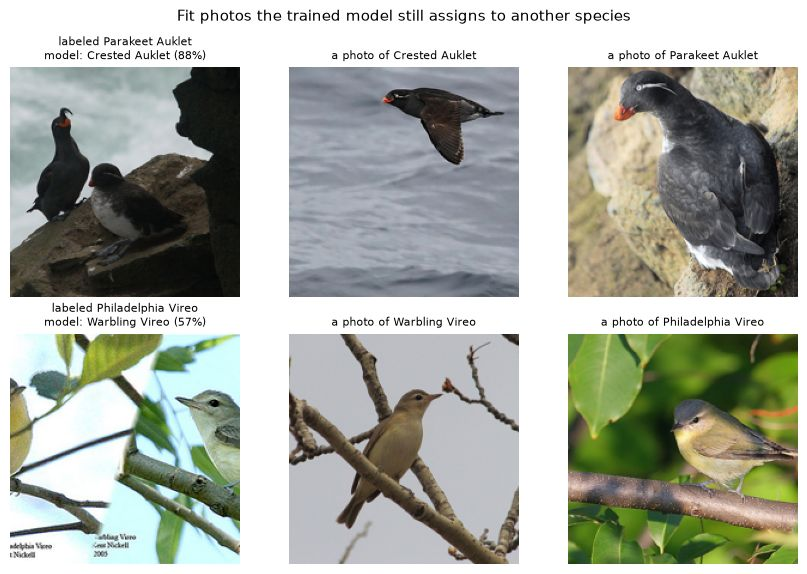

In [28]:
# Score fit and val photos with the classifier
head = model.get_classifier()
W, b = head.weight.detach().float().cpu().numpy(), head.bias.detach().float().cpu().numpy()
train_logits = app["embeddings"] @ W.T + b
answers = train_logits.argmax(1)
print(f"argmax agrees with the answers stored with the embeddings on {np.mean(answers == app['answers']):.2%} of photos")

# Count disagreements with the label
train_probs = softmax(train_logits / app_t)
app_labels = app["labels"].astype(np.int64)
app_val = np.isin(app["files"], list(val_names))
disagree = answers != app_labels
md_table(["photos", "count", "model disagrees with the label", "of which with confidence ≥ 50 %"], [
    [name, m.sum(), (disagree & m).sum(), (disagree & m & (train_probs.max(1) >= 0.5)).sum()]
    for name, m in (("fit (trained on)", ~app_val), ("val (held out)", app_val))])

# Pick the most confident disagreements
candidates = np.flatnonzero(disagree & ~app_val)
candidates = candidates[np.argsort(-train_probs[candidates].max(1), kind="stable")]
shown = candidates[:10]
print(f"showing the {len(shown)} most confident of {len(candidates)} fit photos the model assigns to another species")

# Draw each photo with both species
fig, axes = plt.subplots(len(shown), 3, figsize=(8.5, 2.9 * len(shown)), squeeze=False)
for row, i in zip(axes, shown):
    row[0].imshow(square(DATA / "Train" / app["files"][i], 192))
    row[0].set_title(f"labeled {classes[app_labels[i]]}\nmodel: {classes[answers[i]]} ({pct(train_probs[i].max(), 0)})",
                     fontsize=8)
    row[1].imshow(square(train_photo[answers[i]], 192))
    row[1].set_title(f"a photo of {classes[answers[i]]}", fontsize=8)
    row[2].imshow(square(train_photo[app_labels[i]], 192))
    row[2].set_title(f"a photo of {classes[app_labels[i]]}", fontsize=8)
    for ax in row:
        ax.axis("off")

# Add title and show
fig.suptitle("Fit photos the trained model still assigns to another species", fontsize=11)
fig.tight_layout()
show_jpeg(fig)

The model disagrees with the label on only **2 of the 3,870 fit photos**, and both are byte-identical duplicates from Notebook 1, section 5.1: the auklet pair and the Philadelphia/Warbling Vireo pair. One image with two labels can match only one of them. The third duplicate pair inside `train.txt` has its Tennessee Warbler copy in val, where it is one of the 24 val errors (the model answers Red-eyed Vireo, its fit twin's label). Every other fit photo is fitted, so this audit finds a label error only when another photo contradicts it. A wrong label that nothing contradicts is memorized like a right one.

→ **Decision:** no relabeling; the assignment's labels are used as given, and the duplicates are reported.

## 12. Compute and deployment

### 12.1 Training cost

Each run logged its hardware, throughput and memory (`env.json`, `metrics.jsonl`, `summary.json`).

In [29]:
# Show compute per run
md_table(["run", "GPU", "precision", "epochs (kept)", "training time", "images / s", "min / epoch",
          "peak GPU memory"], [
    [label, env["device"], env["amp"].replace("torch.", ""), f"{s['epochs_trained']} ({s['best_epoch']})",
     f"{s['train_hours']:.2f} h", f"{np.mean([r['train_img_per_s'] for r in rows]):.1f}",
     f"{np.mean([r['epoch_time_s'] for r in rows]) / 60:.1f}", f"{max(r['peak_mem_gb'] for r in rows):.1f} GB"]
    for run, label in ra.SETTINGS_RUNS
    for env, s, rows in [(json.loads((RUN_LOGS / run / "env.json").read_text()),
                          json.loads((RUN_LOGS / run / "summary.json").read_text()),
                          [r for r in read_jsonl(RUN_LOGS / run / "metrics.jsonl") if "epoch" in r])]])

| run | GPU | precision | epochs (kept) | training time | images / s | min / epoch | peak GPU memory |
|---|---|---|---|---|---|---|---|
| ResNet-50 (cosine) | Tesla T4 | float16 | 30 (28) | 0.89 h | 67.5 | 1.8 | 6.3 GB |
| ResNet-50 (plateau) | Tesla T4 | float16 | 51 (35) | 1.50 h | 67.5 | 1.8 | 6.3 GB |
| DINOv3 ViT-L/16 | Tesla T4 | float16 | 30 (17) | 5.29 h | 9.4 | 10.3 | 7.6 GB |
| EVA-02-L | Tesla T4 | float16 | 20 (17) | 6.38 h | 5.2 | 18.6 | 8.0 GB |
| ConvNeXt-L | Tesla T4 | float16 | 20 (10) | 3.49 h | 9.5 | 10.2 | 6.8 GB |

### 12.2 Inference latency on this machine

The web app answers on a CPU: one pass for the photo and one for its mirror, plus Grad-CAM's backward pass when it shows the heat map. The cell times those on laptop's CPU and on its GPU (Apple MPS), after one warm-up run each.

In [30]:
def answer_time(batch: torch.Tensor, explain: bool) -> float:
    """Seconds for the app's work on one photo: photo and mirror, with or without Grad-CAM."""
    start = time.perf_counter()
    if explain:
        grad_cam(model, batch)
    else:
        with torch.no_grad():
            model(batch)
    with torch.no_grad():
        model(torch.flip(batch, dims=[3]))
    synchronize(batch.device)  # MPS runs asynchronously: wait for the work to finish
    return time.perf_counter() - start


# Time each device
x, _ = view_of(test_files[0])
table = []
for name in (["cpu", "mps"] if torch.backends.mps.is_available() else ["cpu"]):
    model.to(name)
    batch = x[None].to(name)
    for explain in (False, True):
        answer_time(batch, explain)
        times = [answer_time(batch, explain) for _ in range(3)]
        table.append([name.upper(), "photo + mirror" + (" + Grad-CAM" if explain else ""),
                      f"{np.median(times):.2f} s"])

# Restore the device and show timings
model.to(device)
md_table(["device", "work per uploaded photo", "median of 3 runs"], table)
print(f"{n_params / 1e6:.0f} M parameters; weights {WEIGHTS.stat().st_size / 1e6:.0f} MB in fp16 "
      f"({n_params * 4 / 1e6:.0f} MB in fp32 once loaded)")

| device | work per uploaded photo | median of 3 runs |
|---|---|---|
| CPU | photo + mirror | 3.87 s |
| CPU | photo + mirror + Grad-CAM | 3.99 s |
| MPS | photo + mirror | 0.13 s |
| MPS | photo + mirror + Grad-CAM | 0.13 s |

199 M parameters; weights 398 MB in fp16 (796 MB in fp32 once loaded)


Training the final model took 3.5 h on one T4 GPU at 9.5 photos per second. The best epoch was 10, so the last 9 of its 20 epochs brought no val gain. EVA-02-L took almost twice as long (6.4 h, 5.2 photos/s) and DINOv3 ViT-L 5.3 h. All fit in at most 8 GB of GPU memory thanks to fp16 and gradient checkpointing.

An uploaded photo costs two forward passes (photo and mirror): about 3.7 s on this laptop's CPU and 0.13 s on its GPU (timings vary by a few percent between runs). Across four runs of this cell, Grad-CAM added between 0 and 0.15 s on the CPU, because its gradient stops at the last feature map instead of running back through the backbone (`birdcls.cam.grad_cam`). The weights take 398 MB stored in fp16 and 796 MB in memory in fp32, which an ordinary laptop can hold.

## Summary

| question | answer | section |
|---|---|---|
| Which pretrained network? | The four best frozen backbones all saw species labels; ConvNeXt-L (CLIP → iNat21) reaches 97.8 % val as a probe, ResNet-50 65.4 % | 7.1 |
| How much CUB data does it need? | One photo per species already gives 90.6 % val; most of the accuracy is in the pretraining | 7.3 |
| What does fine-tuning change? | Little: neighbors in the feature space stay the same (AUC 0.998 before and after); +0.5 pp test over the probe | 7.5, 9.9 |
| Does it overfit? | ConvNeXt-L: 2.5 pp fit–val gap, flat; ResNet-50: 21–23 pp with the same recipe | 8.3 |
| Which training choices matter? | LP-FT and layer-wise learning-rate decay; the six regularizers only together | 8.5, 8.6 |
| How good is the final model? | Test top-1 96.6 % (95.7–97.4), average per-class 96.6 % (95.6–97.4) | 9.1 |
| Is the ensemble better? | +0.5 pp, not significant (p = 0.29 against the final model) | 9.4 |
| What are the errors? | Two thirds are look-alike species; 3 are duplicate photos with another label; a few may be label errors | 9.6, 11 |
| Can the confidence be trusted? | After temperature scaling: ECE 0.015; the app's threshold gives 98.1 % right answers on 94.4 % of test photos | 9.8 |
| Where does the model look? | On the bird, mostly its distinctive parts; with several birds, on each species' own bird | 10 |